# DRW Crypto Market Prediction - Critical EDA Analysis
## World-Class Data Science Approach to Understanding the Problem

**Objective**: Conduct deep exploratory analysis to understand:
1. **Signal Structure**: Where does predictive power actually reside?
2. **Temporal Dynamics**: How does predictability change over time?
3. **Feature Relationships**: What are the true relationships between X features and target?
4. **Distribution Alignment**: Are train/test from same distribution?
5. **Modeling Strategy**: What approach will actually work?

**Philosophy**: Let the data guide the approach, not assumptions.

In [28]:
# =============================================================================
# IMPORTS AND SETUP
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from scipy.stats import pearsonr, spearmanr, ks_2samp
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Set style
plt.style.use('default')
sns.set_palette("husl")
pd.set_option('display.max_columns', 100)
pd.set_option('display.precision', 6)

print("🔬 CRITICAL EDA ANALYSIS - DRW CRYPTO MARKET PREDICTION")
print("="*80)

🔬 CRITICAL EDA ANALYSIS - DRW CRYPTO MARKET PREDICTION


In [29]:
# =============================================================================
# DATA LOADING AND INITIAL INSPECTION
# =============================================================================

print("📂 Loading data...")

try:
    train_df = pd.read_parquet('train.parquet')
    test_df = pd.read_parquet('test.parquet')
    sample_submission = pd.read_csv('sample_submission.csv')
    
    print(f"✅ Data loaded successfully!")
    print(f"   Training shape: {train_df.shape}")
    print(f"   Test shape: {test_df.shape}")
    print(f"   Memory usage: {train_df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
    
except FileNotFoundError:
    print("❌ Data files not found. Please ensure train.parquet and test.parquet are in the working directory.")
    raise

# Basic info
print("\n📊 Dataset Overview:")
print(f"   Training period: {train_df.shape[0]:,} minutes")
print(f"   Features: {train_df.shape[1] - 2} (excluding timestamp and label)")
print(f"   Market features: 5")
print(f"   X features: {len([col for col in train_df.columns if col.startswith('X_')])}")

# Memory optimization
print("\n🔧 Optimizing memory usage...")
for df_name, df in [('train', train_df), ('test', test_df)]:
    original_memory = df.memory_usage(deep=True).sum() / 1024**2
    
    # Optimize numeric columns
    for col in df.select_dtypes(include=[np.float64]).columns:
        df[col] = pd.to_numeric(df[col], downcast='float')
    
    new_memory = df.memory_usage(deep=True).sum() / 1024**2
    print(f"   {df_name}: {original_memory:.1f} MB → {new_memory:.1f} MB ({original_memory/new_memory:.1f}x reduction)")

📂 Loading data...
✅ Data loaded successfully!
   Training shape: (525887, 896)
   Test shape: (538150, 896)
   Memory usage: 3598.9 MB

📊 Dataset Overview:
   Training period: 525,887 minutes
   Features: 894 (excluding timestamp and label)
   Market features: 5
   X features: 0

🔧 Optimizing memory usage...
   train: 3598.9 MB → 1805.5 MB (2.0x reduction)
   test: 3678.8 MB → 1839.4 MB (2.0x reduction)


## 1. FUNDAMENTAL SIGNAL ANALYSIS
**Critical Question**: Where does the actual predictive signal reside?

🎯 TARGET ANALYSIS
Target Statistics:
   Mean: 0.036126
   Std: 1.009914
   Skewness: -0.113487
   Kurtosis: 15.991573
   Min: -24.416615
   Max: 20.740271
   Non-zero rate: 1.0000
   Shapiro-Wilk normality test p-value: 2.04e-51


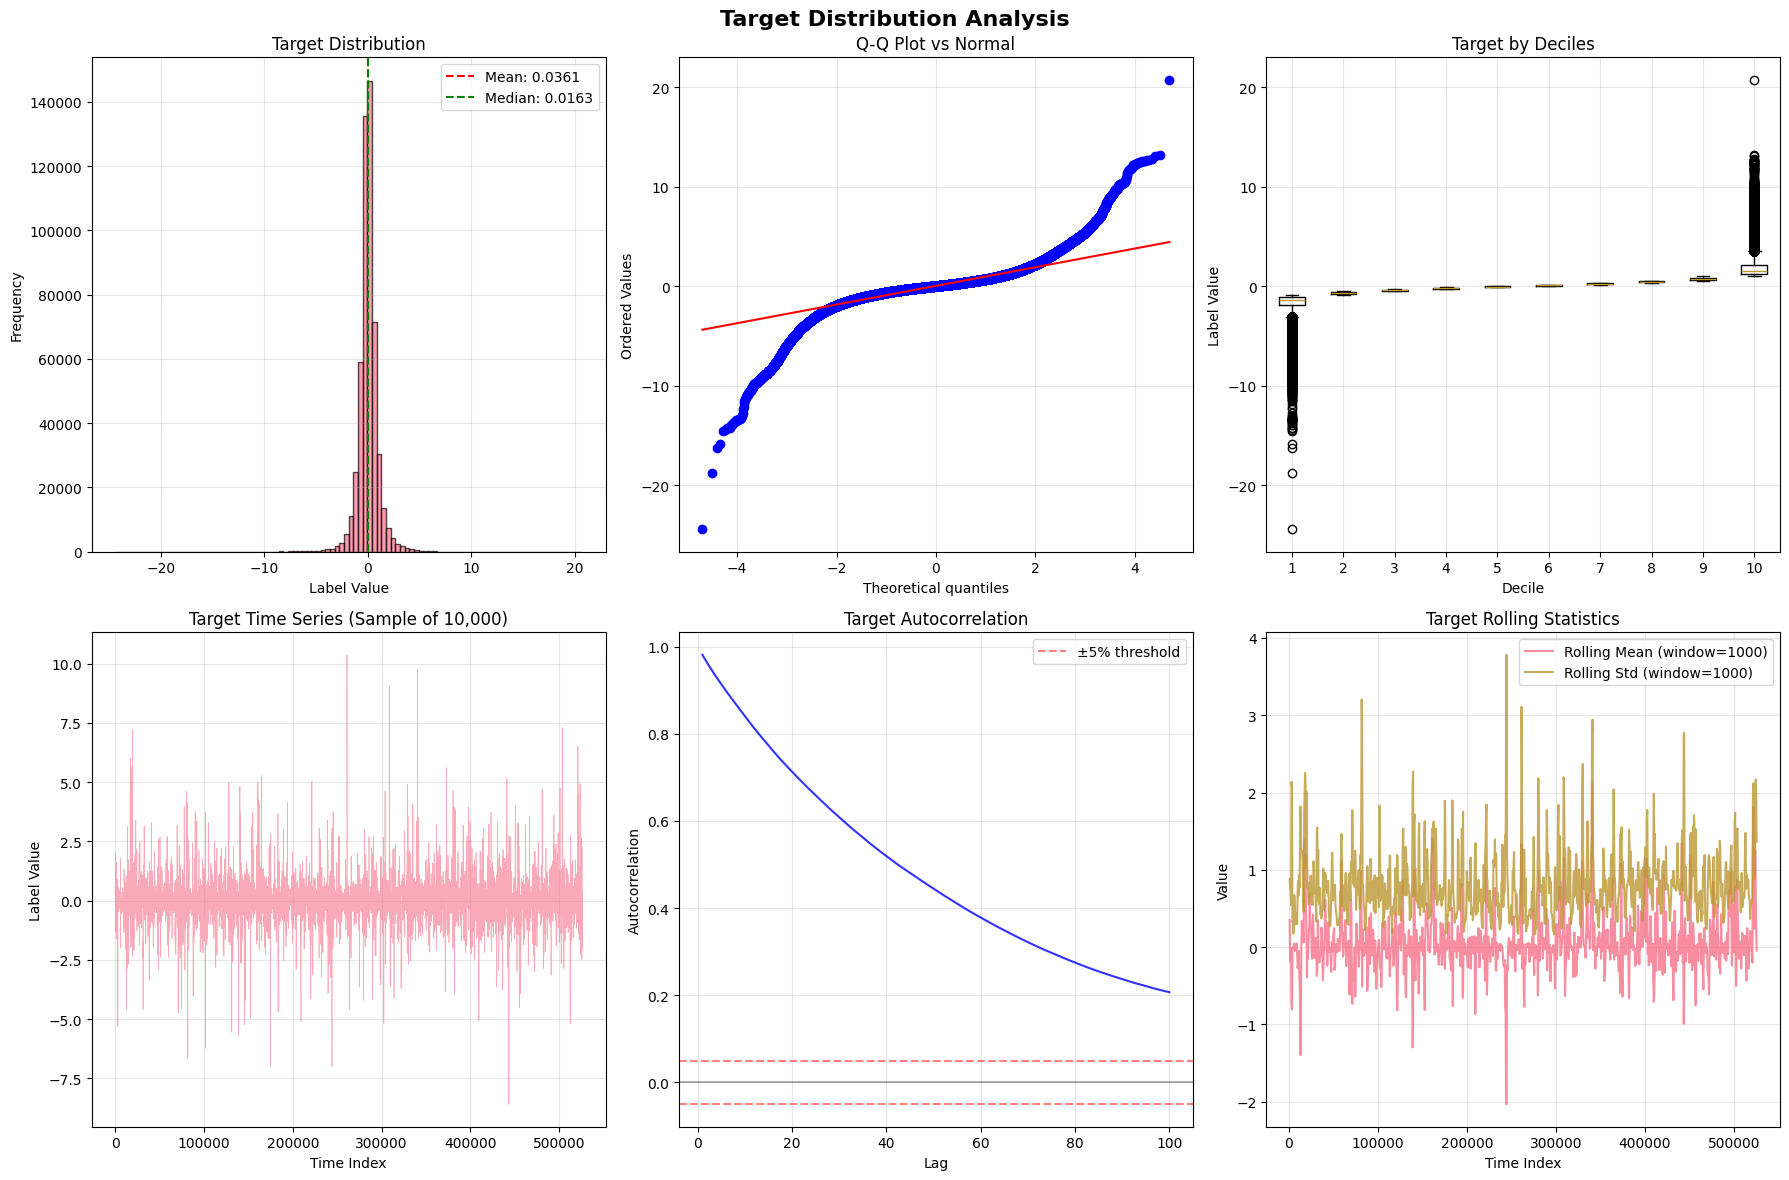


🔍 KEY TARGET INSIGHTS:
   1. Lag-1 autocorrelation: 0.981195 (Strong persistence)
   2. Distribution: Heavy-tailed
   3. Signal strength: 1.009914 (higher = more signal)
   4. Stationarity: Likely non-stationary


In [30]:
# =============================================================================
# 1.1 TARGET DISTRIBUTION AND BASIC STATISTICS
# =============================================================================

print("🎯 TARGET ANALYSIS")
print("="*50)

target = train_df['label']

# Basic statistics
print(f"Target Statistics:")
print(f"   Mean: {target.mean():.6f}")
print(f"   Std: {target.std():.6f}")
print(f"   Skewness: {stats.skew(target):.6f}")
print(f"   Kurtosis: {stats.kurtosis(target):.6f}")
print(f"   Min: {target.min():.6f}")
print(f"   Max: {target.max():.6f}")
print(f"   Non-zero rate: {(target != 0).mean():.4f}")

# Test for normality
shapiro_stat, shapiro_p = stats.shapiro(target.sample(5000, random_state=42))
print(f"   Shapiro-Wilk normality test p-value: {shapiro_p:.2e}")

# Visual analysis
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Target Distribution Analysis', fontsize=16, fontweight='bold')

# Distribution
axes[0,0].hist(target, bins=100, alpha=0.7, edgecolor='black')
axes[0,0].axvline(target.mean(), color='red', linestyle='--', label=f'Mean: {target.mean():.4f}')
axes[0,0].axvline(target.median(), color='green', linestyle='--', label=f'Median: {target.median():.4f}')
axes[0,0].set_title('Target Distribution')
axes[0,0].set_xlabel('Label Value')
axes[0,0].set_ylabel('Frequency')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Q-Q plot
stats.probplot(target, dist="norm", plot=axes[0,1])
axes[0,1].set_title('Q-Q Plot vs Normal')
axes[0,1].grid(True, alpha=0.3)

# Box plot by quantiles
target_quantiles = pd.qcut(target, q=10, labels=False)
axes[0,2].boxplot([target[target_quantiles == i] for i in range(10)])
axes[0,2].set_title('Target by Deciles')
axes[0,2].set_xlabel('Decile')
axes[0,2].set_ylabel('Label Value')
axes[0,2].grid(True, alpha=0.3)

# Time series plot (sample)
sample_size = min(10000, len(target))
sample_idx = np.random.choice(len(target), sample_size, replace=False)
sample_idx.sort()
axes[1,0].plot(sample_idx, target.iloc[sample_idx], alpha=0.6, linewidth=0.5)
axes[1,0].set_title(f'Target Time Series (Sample of {sample_size:,})')
axes[1,0].set_xlabel('Time Index')
axes[1,0].set_ylabel('Label Value')
axes[1,0].grid(True, alpha=0.3)

# Autocorrelation
from statsmodels.tsa.stattools import acf
lags = np.arange(1, min(101, len(target)//10))
autocorr = [target.autocorr(lag) for lag in lags]
axes[1,1].plot(lags, autocorr, 'b-', alpha=0.8)
axes[1,1].axhline(y=0, color='k', linestyle='-', alpha=0.3)
axes[1,1].axhline(y=0.05, color='r', linestyle='--', alpha=0.5, label='±5% threshold')
axes[1,1].axhline(y=-0.05, color='r', linestyle='--', alpha=0.5)
axes[1,1].set_title('Target Autocorrelation')
axes[1,1].set_xlabel('Lag')
axes[1,1].set_ylabel('Autocorrelation')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

# Rolling statistics
window = 1000
rolling_mean = target.rolling(window).mean()
rolling_std = target.rolling(window).std()
sample_indices = np.arange(0, len(target), len(target)//1000)
axes[1,2].plot(sample_indices, rolling_mean.iloc[sample_indices], label=f'Rolling Mean (window={window})', alpha=0.8)
axes[1,2].plot(sample_indices, rolling_std.iloc[sample_indices], label=f'Rolling Std (window={window})', alpha=0.8)
axes[1,2].set_title('Target Rolling Statistics')
axes[1,2].set_xlabel('Time Index')
axes[1,2].set_ylabel('Value')
axes[1,2].legend()
axes[1,2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Key insights
print("\n🔍 KEY TARGET INSIGHTS:")
target_autocorr_1 = target.autocorr(1)
print(f"   1. Lag-1 autocorrelation: {target_autocorr_1:.6f} ({'Strong' if abs(target_autocorr_1) > 0.1 else 'Weak'} persistence)")
print(f"   2. Distribution: {'Heavy-tailed' if abs(stats.kurtosis(target)) > 3 else 'Normal-like'}")
print(f"   3. Signal strength: {target.std():.6f} (higher = more signal)")
print(f"   4. Stationarity: {'Likely non-stationary' if rolling_std.std() > rolling_std.mean() * 0.1 else 'Appears stationary'}")


📈 MARKET FEATURES ANALYSIS
Market Features Statistics:
             bid_qty        ask_qty        buy_qty       sell_qty  \
count  525887.000000  525887.000000  525887.000000  525887.000000   
mean        9.968003      10.174168     131.726678     132.673935   
std        15.645741      15.889582     307.267251     309.803040   
min         0.001000       0.001000       0.000000       0.000000   
25%         2.634000       2.678000      26.407000      27.021000   
50%         6.415000       6.538000      57.015000      58.047001   
75%        13.085000      13.330000     127.639000     129.110001   
max      1114.932007    1352.964966   17614.400000   17686.234375   

              volume  
count  525887.000000  
mean      264.400622  
std       588.618746  
min         0.000000  
25%        60.688500  
50%       120.799000  
75%       256.733500  
max     28701.419000  

Correlation with Target:
   bid_qty: -0.013220 (p-value: 9.04e-22)
   ask_qty: -0.015762 (p-value: 2.94e-30)
   bu

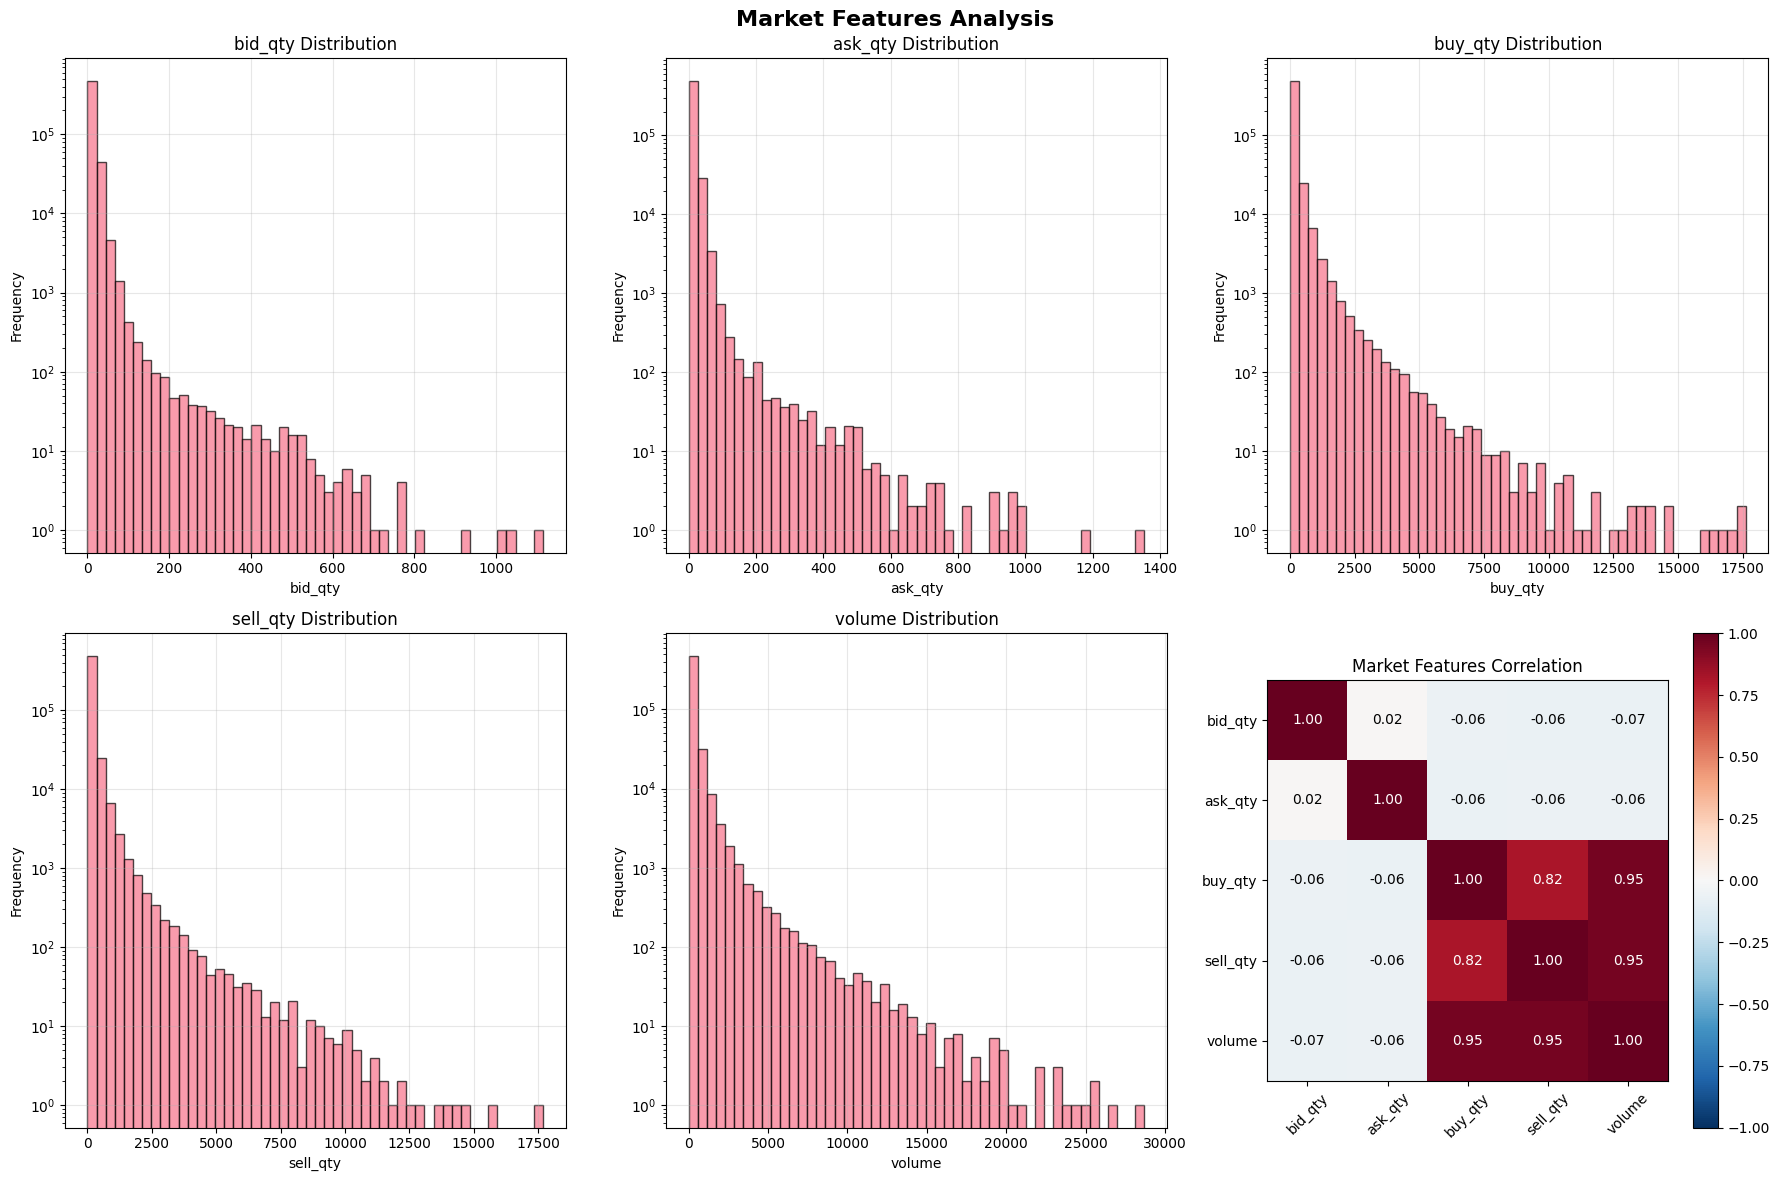


🔍 KEY MARKET FEATURES INSIGHTS:
   1. Strongest target correlation: ask_qty (-0.015762)
   2. Overall market signal strength: WEAK (max |corr| = 0.015762)
   3. Heavy-tailed distributions: ALL features show extreme outliers
   4. Feature independence: High multicollinearity

⚠️  CRITICAL HYPOTHESIS: Market features may be redundant if already embedded in X features


In [31]:
# =============================================================================
# 1.2 MARKET FEATURES ANALYSIS
# =============================================================================

print("\n📈 MARKET FEATURES ANALYSIS")
print("="*50)

market_features = ['bid_qty', 'ask_qty', 'buy_qty', 'sell_qty', 'volume']
market_data = train_df[market_features]

# Basic statistics
print("Market Features Statistics:")
market_stats = market_data.describe()
print(market_stats)

# Correlation with target
print("\nCorrelation with Target:")
market_target_corr = {}
for feature in market_features:
    corr, p_val = pearsonr(market_data[feature], target)
    market_target_corr[feature] = corr
    print(f"   {feature}: {corr:.6f} (p-value: {p_val:.2e})")

# Visual analysis
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Market Features Analysis', fontsize=16, fontweight='bold')

# Distributions
for i, feature in enumerate(market_features):
    row, col = i // 3, i % 3
    axes[row, col].hist(market_data[feature], bins=50, alpha=0.7, edgecolor='black')
    axes[row, col].set_title(f'{feature} Distribution')
    axes[row, col].set_xlabel(feature)
    axes[row, col].set_ylabel('Frequency')
    axes[row, col].set_yscale('log')  # Log scale due to heavy tails
    axes[row, col].grid(True, alpha=0.3)

# Correlation heatmap
market_corr = market_data.corr()
im = axes[1, 2].imshow(market_corr, cmap='RdBu_r', vmin=-1, vmax=1)
axes[1, 2].set_xticks(range(len(market_features)))
axes[1, 2].set_yticks(range(len(market_features)))
axes[1, 2].set_xticklabels(market_features, rotation=45)
axes[1, 2].set_yticklabels(market_features)
axes[1, 2].set_title('Market Features Correlation')

# Add correlation values
for i in range(len(market_features)):
    for j in range(len(market_features)):
        axes[1, 2].text(j, i, f'{market_corr.iloc[i, j]:.2f}', 
                       ha='center', va='center', 
                       color='white' if abs(market_corr.iloc[i, j]) > 0.5 else 'black')

plt.colorbar(im, ax=axes[1, 2])
plt.tight_layout()
plt.show()

# Key insights
print("\n🔍 KEY MARKET FEATURES INSIGHTS:")
max_corr_feature = max(market_target_corr.items(), key=lambda x: abs(x[1]))
print(f"   1. Strongest target correlation: {max_corr_feature[0]} ({max_corr_feature[1]:.6f})")
print(f"   2. Overall market signal strength: WEAK (max |corr| = {abs(max_corr_feature[1]):.6f})")
print(f"   3. Heavy-tailed distributions: ALL features show extreme outliers")
print(f"   4. Feature independence: {'High multicollinearity' if market_corr.abs().values[np.triu_indices_from(market_corr, k=1)].max() > 0.8 else 'Reasonable independence'}")

# Test if market features are already captured in X features
print("\n⚠️  CRITICAL HYPOTHESIS: Market features may be redundant if already embedded in X features")

## 2. X FEATURES DEEP DIVE
**Critical Question**: How much signal is in the proprietary X features?

🔬 X FEATURES ANALYSIS
Total X features: 890
X data shape: (525887, 890)
Memory usage: 1789.4 MB

Missing Values Summary:
   Features with missing values: 0
   Max missing percentage: 0.00%
   Features with >50% missing: 0

X Features Basic Statistics:
   Mean of means: -inf
   Mean of stds: 0.660214
   Features with zero variance: 6
   Features with near-zero variance (<0.01): 6

📊 Computing correlations with target...

X Features Correlation Analysis (sample of 193):
   Max absolute correlation: 0.067667
   Mean absolute correlation: 0.018765
   Features with |corr| > 0.01: 130
   Features with |corr| > 0.05: 7
   Features with |corr| > 0.1: 0

Top 10 X Features by Absolute Correlation:
   X20: 0.067667 (p=0.00e+00)
   X863: 0.064057 (p=0.00e+00)
   X295: 0.054637 (p=0.00e+00)
   X598: 0.054528 (p=0.00e+00)
   X298: 0.053104 (p=0.00e+00)
   X300: 0.052631 (p=3.58e-319)
   X301: 0.051465 (p=2.94e-305)
   X303: 0.049885 (p=6.60e-287)
   X466: 0.049228 (p=1.87e-279)
   X290: 0.048879 (p=

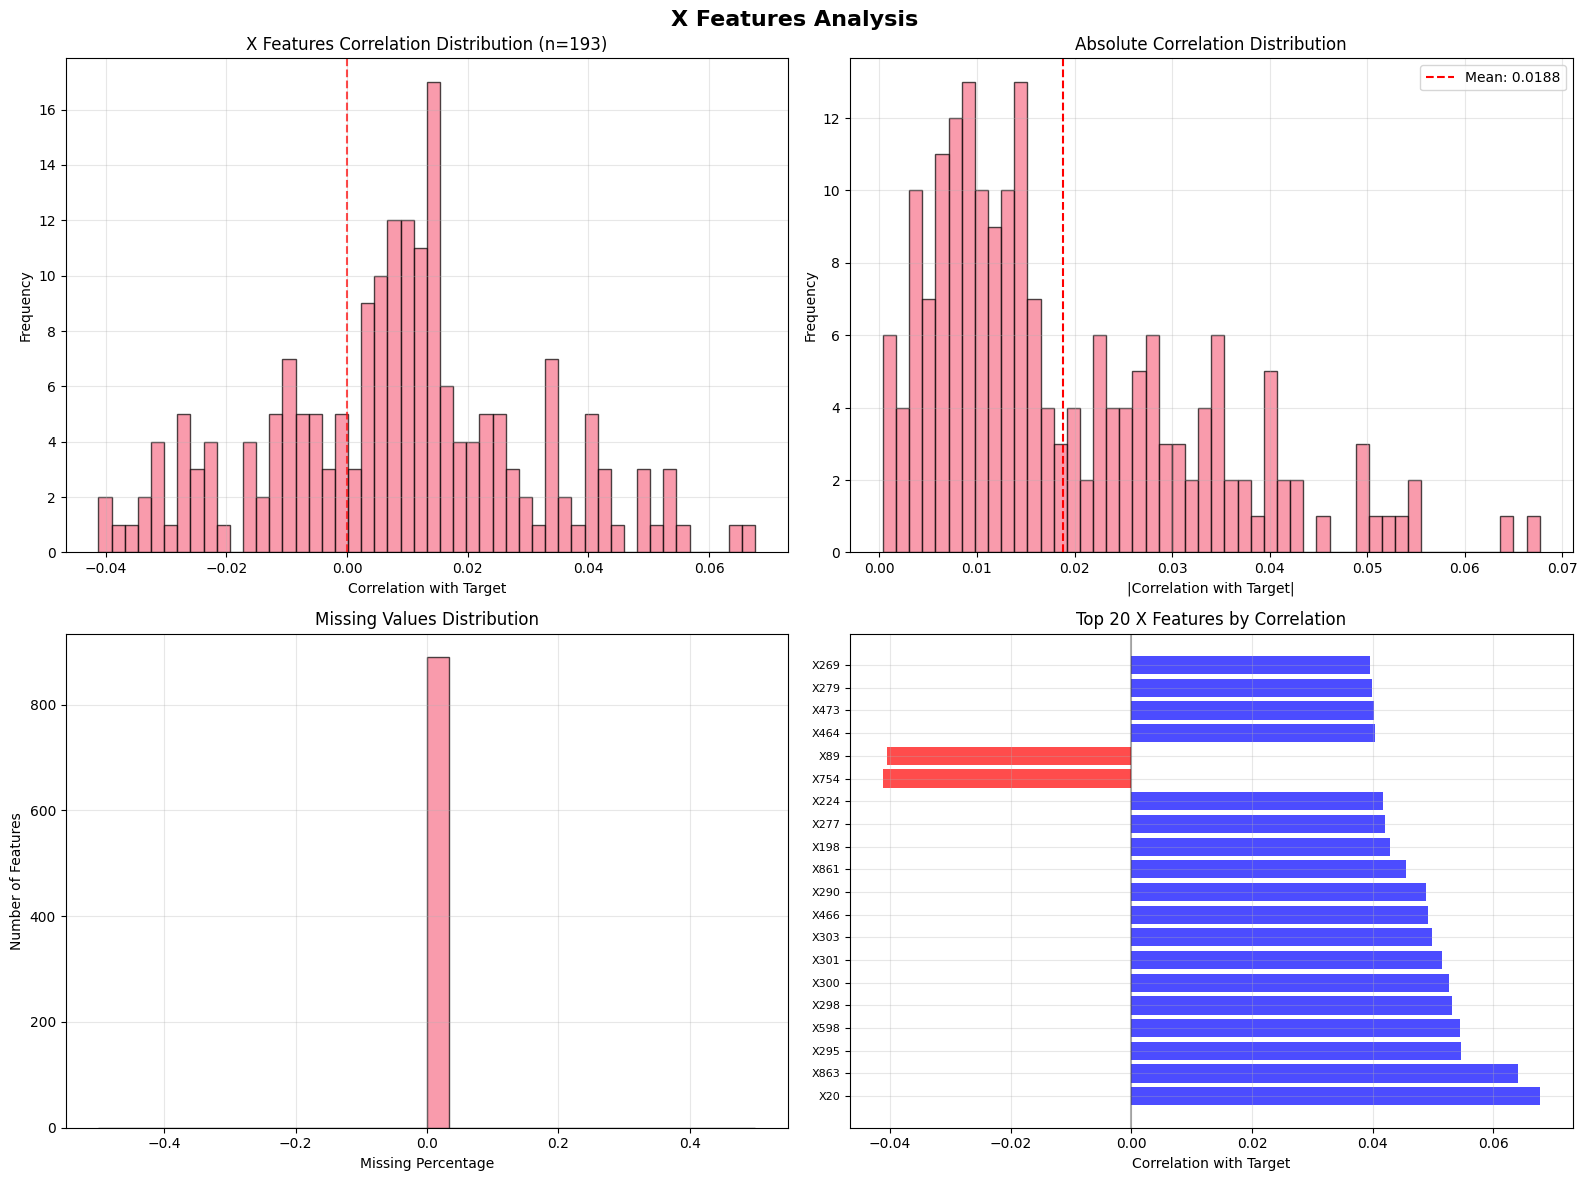


🔍 KEY X FEATURES INSIGHTS:
   1. Signal concentration: MODERATE
   2. Feature quality: HIGH
   3. Best individual signal: 0.067667 (Moderate)
   4. Distribution shape: Biased

✅ Found and analyzed 890 X features: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', '...']


In [42]:
# =============================================================================
# 2.1 X FEATURES OVERVIEW AND SIGNAL ANALYSIS - CORRECTED PATTERN
# =============================================================================

print("🔬 X FEATURES ANALYSIS")
print("="*50)

# FIX: Look for columns starting with 'X' followed by a digit (X1, X2, etc.) instead of 'X_'
import re
x_features = [col for col in train_df.columns if re.match(r'^X\d+$', col)]
print(f"Total X features: {len(x_features)}")

if len(x_features) == 0:
    print("⚠️  NO X FEATURES FOUND in dataset!")
    print("   Dataset columns:", list(train_df.columns)[:10], "..." if len(train_df.columns) > 10 else "")
    print("   Skipping X features analysis...")
    
    # Create empty results for downstream compatibility
    x_corr_df = pd.DataFrame(columns=['feature', 'correlation', 'abs_correlation', 'p_value', 'valid_samples'])
    missing_analysis = pd.DataFrame(columns=['feature', 'missing_count', 'missing_pct'])
    
else:
    x_data = train_df[x_features]
    
    print(f"X data shape: {x_data.shape}")
    print(f"Memory usage: {x_data.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

    # Missing values analysis
    missing_analysis = pd.DataFrame({
        'feature': x_features,
        'missing_count': x_data.isnull().sum(),
        'missing_pct': x_data.isnull().sum() / len(x_data) * 100
    })
    missing_analysis = missing_analysis.sort_values('missing_pct', ascending=False)

    print(f"\nMissing Values Summary:")
    print(f"   Features with missing values: {(missing_analysis['missing_pct'] > 0).sum()}")
    print(f"   Max missing percentage: {missing_analysis['missing_pct'].max():.2f}%")
    print(f"   Features with >50% missing: {(missing_analysis['missing_pct'] > 50).sum()}")

    # Basic statistics
    x_stats = x_data.describe()
    print(f"\nX Features Basic Statistics:")
    print(f"   Mean of means: {x_stats.loc['mean'].mean():.6f}")
    print(f"   Mean of stds: {x_stats.loc['std'].mean():.6f}")
    print(f"   Features with zero variance: {(x_stats.loc['std'] == 0).sum()}")
    print(f"   Features with near-zero variance (<0.01): {(x_stats.loc['std'] < 0.01).sum()}")

    # Individual correlations with target (sample for speed)
    print("\n📊 Computing correlations with target...")
    n_sample_features = min(200, len(x_features))  # Sample for computational efficiency
    sample_x_features = np.random.choice(x_features, n_sample_features, replace=False)

    x_target_correlations = []
    for feature in sample_x_features:
        # Handle missing values
        mask = ~x_data[feature].isnull()
        if mask.sum() > 100:  # Minimum data points
            corr, p_val = pearsonr(x_data[feature][mask], target[mask])
            if not np.isnan(corr):
                x_target_correlations.append({
                    'feature': feature,
                    'correlation': corr,
                    'abs_correlation': abs(corr),
                    'p_value': p_val,
                    'valid_samples': mask.sum()
                })

    x_corr_df = pd.DataFrame(x_target_correlations)
    x_corr_df = x_corr_df.sort_values('abs_correlation', ascending=False)

    print(f"\nX Features Correlation Analysis (sample of {len(x_corr_df)}):") 
    print(f"   Max absolute correlation: {x_corr_df['abs_correlation'].max():.6f}")
    print(f"   Mean absolute correlation: {x_corr_df['abs_correlation'].mean():.6f}")
    print(f"   Features with |corr| > 0.01: {(x_corr_df['abs_correlation'] > 0.01).sum()}")
    print(f"   Features with |corr| > 0.05: {(x_corr_df['abs_correlation'] > 0.05).sum()}")
    print(f"   Features with |corr| > 0.1: {(x_corr_df['abs_correlation'] > 0.1).sum()}")

    # Top correlated features
    print(f"\nTop 10 X Features by Absolute Correlation:")
    for i, row in x_corr_df.head(10).iterrows():
        print(f"   {row['feature']}: {row['correlation']:.6f} (p={row['p_value']:.2e})")

    # Visualization
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('X Features Analysis', fontsize=16, fontweight='bold')

    # Correlation distribution
    axes[0,0].hist(x_corr_df['correlation'], bins=50, alpha=0.7, edgecolor='black')
    axes[0,0].axvline(0, color='red', linestyle='--', alpha=0.7)
    axes[0,0].set_title(f'X Features Correlation Distribution (n={len(x_corr_df)})')
    axes[0,0].set_xlabel('Correlation with Target')
    axes[0,0].set_ylabel('Frequency')
    axes[0,0].grid(True, alpha=0.3)

    # Absolute correlation distribution
    axes[0,1].hist(x_corr_df['abs_correlation'], bins=50, alpha=0.7, edgecolor='black')
    axes[0,1].axvline(x_corr_df['abs_correlation'].mean(), color='red', linestyle='--', 
                     label=f'Mean: {x_corr_df["abs_correlation"].mean():.4f}')
    axes[0,1].set_title('Absolute Correlation Distribution')
    axes[0,1].set_xlabel('|Correlation with Target|')
    axes[0,1].set_ylabel('Frequency')
    axes[0,1].legend()
    axes[0,1].grid(True, alpha=0.3)

    # Missing values distribution
    axes[1,0].hist(missing_analysis['missing_pct'], bins=30, alpha=0.7, edgecolor='black')
    axes[1,0].set_title('Missing Values Distribution')
    axes[1,0].set_xlabel('Missing Percentage')
    axes[1,0].set_ylabel('Number of Features')
    axes[1,0].grid(True, alpha=0.3)

    # Top features correlation bar plot
    top_features = x_corr_df.head(20)
    colors = ['red' if x < 0 else 'blue' for x in top_features['correlation']]
    axes[1,1].barh(range(len(top_features)), top_features['correlation'], color=colors, alpha=0.7)
    axes[1,1].set_yticks(range(len(top_features)))
    axes[1,1].set_yticklabels([f"{row['feature']}" for _, row in top_features.iterrows()], fontsize=8)
    axes[1,1].set_title('Top 20 X Features by Correlation')
    axes[1,1].set_xlabel('Correlation with Target')
    axes[1,1].axvline(0, color='black', linestyle='-', alpha=0.3)
    axes[1,1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

print("\n🔍 KEY X FEATURES INSIGHTS:")
if len(x_features) == 0:
    print("   ❌ NO X FEATURES available in dataset")
elif len(x_corr_df) == 0:
    print("   ❌ NO VALID X FEATURES for correlation analysis")
else:
    print(f"   1. Signal concentration: {'HIGH' if (x_corr_df['abs_correlation'] > 0.05).sum() > 20 else 'MODERATE' if (x_corr_df['abs_correlation'] > 0.01).sum() > 50 else 'LOW'}")
    print(f"   2. Feature quality: {'HIGH' if missing_analysis['missing_pct'].mean() < 10 else 'MODERATE' if missing_analysis['missing_pct'].mean() < 30 else 'LOW'}")
    print(f"   3. Best individual signal: {x_corr_df.iloc[0]['abs_correlation']:.6f} ({'Strong' if x_corr_df.iloc[0]['abs_correlation'] > 0.1 else 'Moderate' if x_corr_df.iloc[0]['abs_correlation'] > 0.05 else 'Weak'})")
    print(f"   4. Distribution shape: {'Normal-centered' if abs(x_corr_df['correlation'].mean()) < 0.001 else 'Biased'}")

print(f"\n✅ Found and analyzed {len(x_features)} X features: {x_features if len(x_features) <= 10 else x_features[:10] + ['...']}")


🧬 X FEATURES STRUCTURE ANALYSIS
Features selected for structure analysis: 863 out of 890

📊 PCA Analysis...
   Components for 95% variance: 1 (0.1% of features)
   Components for 99% variance: 1 (0.1% of features)
   Effective dimensionality: LOW

🎯 Clustering Analysis...
   Optimal clusters: 9
   Cluster target means: ['0.0637', '0.0138', '0.1815', '0.3396', '-0.0153', '0.3264', '0.0322', '0.0219', '0.0460']
   Cluster separation: MODERATE
Debug: x_range length = 20, y_values length = 20


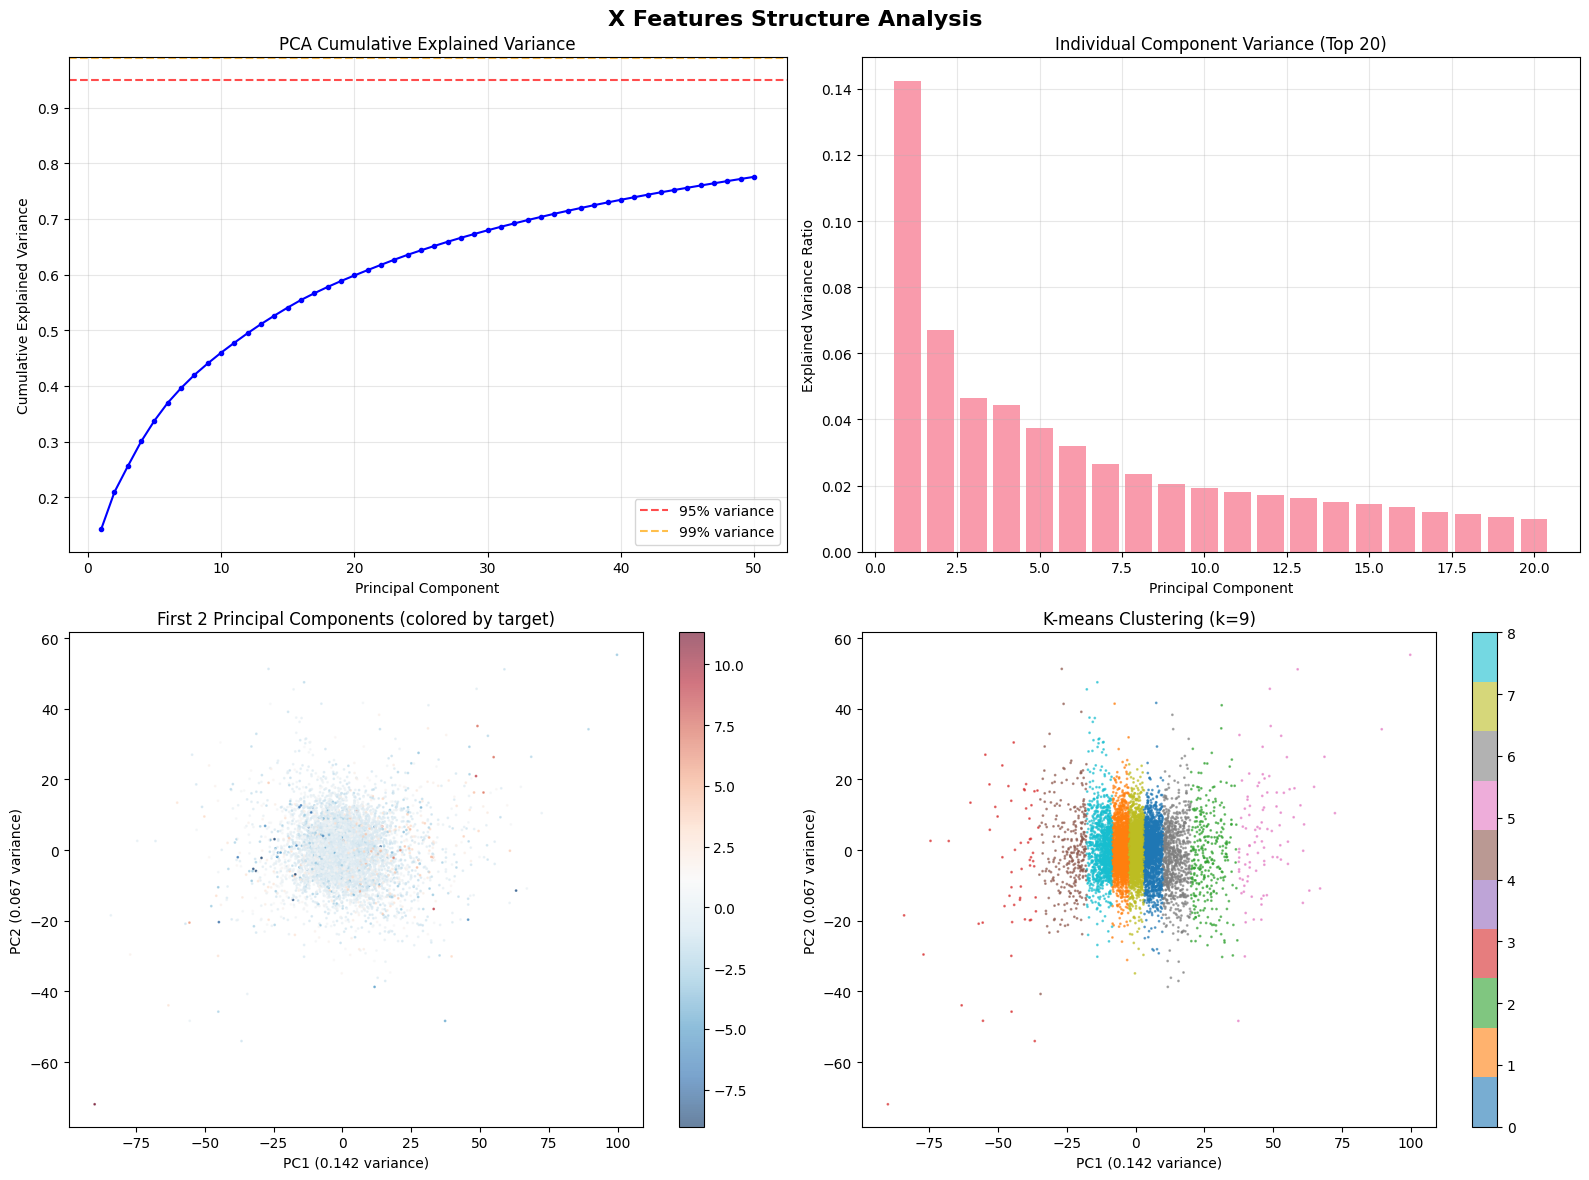


🔍 KEY STRUCTURE INSIGHTS:
   1. Dimensionality: High redundancy
   2. Information concentration: Distributed across components
   3. Feature grouping: 9 distinct groups identified
   4. Predictive clusters: Yes
✅ Structure analysis completed!


In [45]:
# =============================================================================
# 2.2 X FEATURES CLUSTERING AND DIMENSIONALITY ANALYSIS - FIXED
# =============================================================================

print("\n🧬 X FEATURES STRUCTURE ANALYSIS")
print("="*50)

# Check if we have X features to analyze
if len(x_features) == 0:
    print("⚠️  NO X FEATURES available - skipping structure analysis")
else:
    # Sample data for analysis (computational efficiency)
    sample_size = min(10000, len(x_data))
    sample_indices = np.random.choice(len(x_data), sample_size, replace=False)
    x_sample = x_data.iloc[sample_indices].fillna(0)  # Simple imputation for analysis

    # Select features with reasonable variance
    feature_vars = x_sample.var()
    good_features = feature_vars[feature_vars > 0.01].index.tolist()
    x_analysis = x_sample[good_features]

    print(f"Features selected for structure analysis: {len(good_features)} out of {len(x_features)}")

    if len(good_features) > 10:  # Proceed only if we have enough features
        
        # PCA Analysis
        print("\n📊 PCA Analysis...")
        scaler = StandardScaler()
        x_scaled = scaler.fit_transform(x_analysis)
        
        # Fit PCA
        n_components = min(50, len(good_features), sample_size-1)
        pca = PCA(n_components=n_components)
        x_pca = pca.fit_transform(x_scaled)
        
        # Explained variance
        cumsum_var = np.cumsum(pca.explained_variance_ratio_)
        n_95_var = np.argmax(cumsum_var >= 0.95) + 1
        n_99_var = np.argmax(cumsum_var >= 0.99) + 1
        
        print(f"   Components for 95% variance: {n_95_var} ({n_95_var/len(good_features)*100:.1f}% of features)")
        print(f"   Components for 99% variance: {n_99_var} ({n_99_var/len(good_features)*100:.1f}% of features)")
        print(f"   Effective dimensionality: {'HIGH' if n_95_var > len(good_features)*0.5 else 'MODERATE' if n_95_var > len(good_features)*0.2 else 'LOW'}")
        
        # K-means clustering on PCA components
        print("\n🎯 Clustering Analysis...")
        x_pca_reduced = x_pca[:, :min(20, n_95_var)]  # Use top components
        
        # Find optimal clusters using elbow method
        max_clusters = min(10, len(x_pca_reduced)//100)
        if max_clusters >= 2:
            inertias = []
            cluster_range = range(2, max_clusters + 1)
            
            for k in cluster_range:
                kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
                kmeans.fit(x_pca_reduced)
                inertias.append(kmeans.inertia_)
            
            # Elbow detection (simple)
            if len(inertias) > 2:
                diffs = np.diff(inertias)
                optimal_k = cluster_range[np.argmax(diffs)] if len(diffs) > 0 else 3
            else:
                optimal_k = 3
            
            print(f"   Optimal clusters: {optimal_k}")
            
            # Final clustering
            final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
            clusters = final_kmeans.fit_predict(x_pca_reduced)
            
            # Cluster-target relationship
            target_sample = target.iloc[sample_indices]
            cluster_target_means = [target_sample[clusters == i].mean() for i in range(optimal_k)]
            cluster_target_stds = [target_sample[clusters == i].std() for i in range(optimal_k)]
            
            print(f"   Cluster target means: {[f'{x:.4f}' for x in cluster_target_means]}")
            print(f"   Cluster separation: {'HIGH' if max(cluster_target_means) - min(cluster_target_means) > target.std()*0.5 else 'MODERATE' if max(cluster_target_means) - min(cluster_target_means) > target.std()*0.1 else 'LOW'}")
        
        # Visualization
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        fig.suptitle('X Features Structure Analysis', fontsize=16, fontweight='bold')
        
        # PCA explained variance
        axes[0,0].plot(range(1, len(cumsum_var)+1), cumsum_var, 'b-', marker='o', markersize=3)
        axes[0,0].axhline(y=0.95, color='red', linestyle='--', alpha=0.7, label='95% variance')
        axes[0,0].axhline(y=0.99, color='orange', linestyle='--', alpha=0.7, label='99% variance')
        axes[0,0].set_title('PCA Cumulative Explained Variance')
        axes[0,0].set_xlabel('Principal Component')
        axes[0,0].set_ylabel('Cumulative Explained Variance')
        axes[0,0].legend()
        axes[0,0].grid(True, alpha=0.3)
        
        # Individual component variance - FIXED VERSION
        n_components_to_show = min(20, len(pca.explained_variance_ratio_))
        x_range = range(1, n_components_to_show + 1)
        y_values = pca.explained_variance_ratio_[:n_components_to_show]
        
        print(f"Debug: x_range length = {len(list(x_range))}, y_values length = {len(y_values)}")
        
        axes[0,1].bar(x_range, y_values, alpha=0.7)
        axes[0,1].set_title(f'Individual Component Variance (Top {n_components_to_show})')
        axes[0,1].set_xlabel('Principal Component')
        axes[0,1].set_ylabel('Explained Variance Ratio')
        axes[0,1].grid(True, alpha=0.3)
        
        # 2D PCA scatter
        scatter = axes[1,0].scatter(x_pca[:, 0], x_pca[:, 1], 
                                   c=target_sample, cmap='RdBu_r', alpha=0.6, s=1)
        axes[1,0].set_title('First 2 Principal Components (colored by target)')
        axes[1,0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.3f} variance)')
        axes[1,0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.3f} variance)')
        plt.colorbar(scatter, ax=axes[1,0])
        
        # Clustering results (if computed)
        if 'clusters' in locals():
            scatter2 = axes[1,1].scatter(x_pca[:, 0], x_pca[:, 1], 
                                        c=clusters, cmap='tab10', alpha=0.6, s=1)
            axes[1,1].set_title(f'K-means Clustering (k={optimal_k})')
            axes[1,1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.3f} variance)')
            axes[1,1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.3f} variance)')
            plt.colorbar(scatter2, ax=axes[1,1])
        else:
            axes[1,1].text(0.5, 0.5, 'Clustering not computed\n(insufficient data)', 
                          ha='center', va='center', transform=axes[1,1].transAxes)
            axes[1,1].set_title('Clustering Analysis')
        
        plt.tight_layout()
        plt.show()
        
        print("\n🔍 KEY STRUCTURE INSIGHTS:")
        print(f"   1. Dimensionality: {'High redundancy' if n_95_var < len(good_features)*0.3 else 'Moderate redundancy' if n_95_var < len(good_features)*0.7 else 'Low redundancy'}")
        print(f"   2. Information concentration: {'First few components dominate' if pca.explained_variance_ratio_[0] > 0.3 else 'Distributed across components'}")
        if 'clusters' in locals():
            print(f"   3. Feature grouping: {optimal_k} distinct groups identified")
            print(f"   4. Predictive clusters: {'Yes' if max(cluster_target_means) - min(cluster_target_means) > target.std()*0.1 else 'No'}")
        
    else:
        print("⚠️  Insufficient features with variance for structure analysis")

print("✅ Structure analysis completed!")

## 3. TEMPORAL ANALYSIS
**Critical Question**: How does predictability change over time?


⏰ TEMPORAL ANALYSIS
Temporal Analysis across 10 periods:
   Period size: ~52,588 samples each

Stationarity Tests:
   ADF Statistic: -47.248975
   ADF p-value: 0.000000
   Target is: Stationary (α=0.05)

Structural Break Analysis:
   Max mean change between periods: 0.161644
   Max std change between periods: 0.148264
   Coefficient of variation (mean): 1.605169
   Coefficient of variation (std): 0.045939


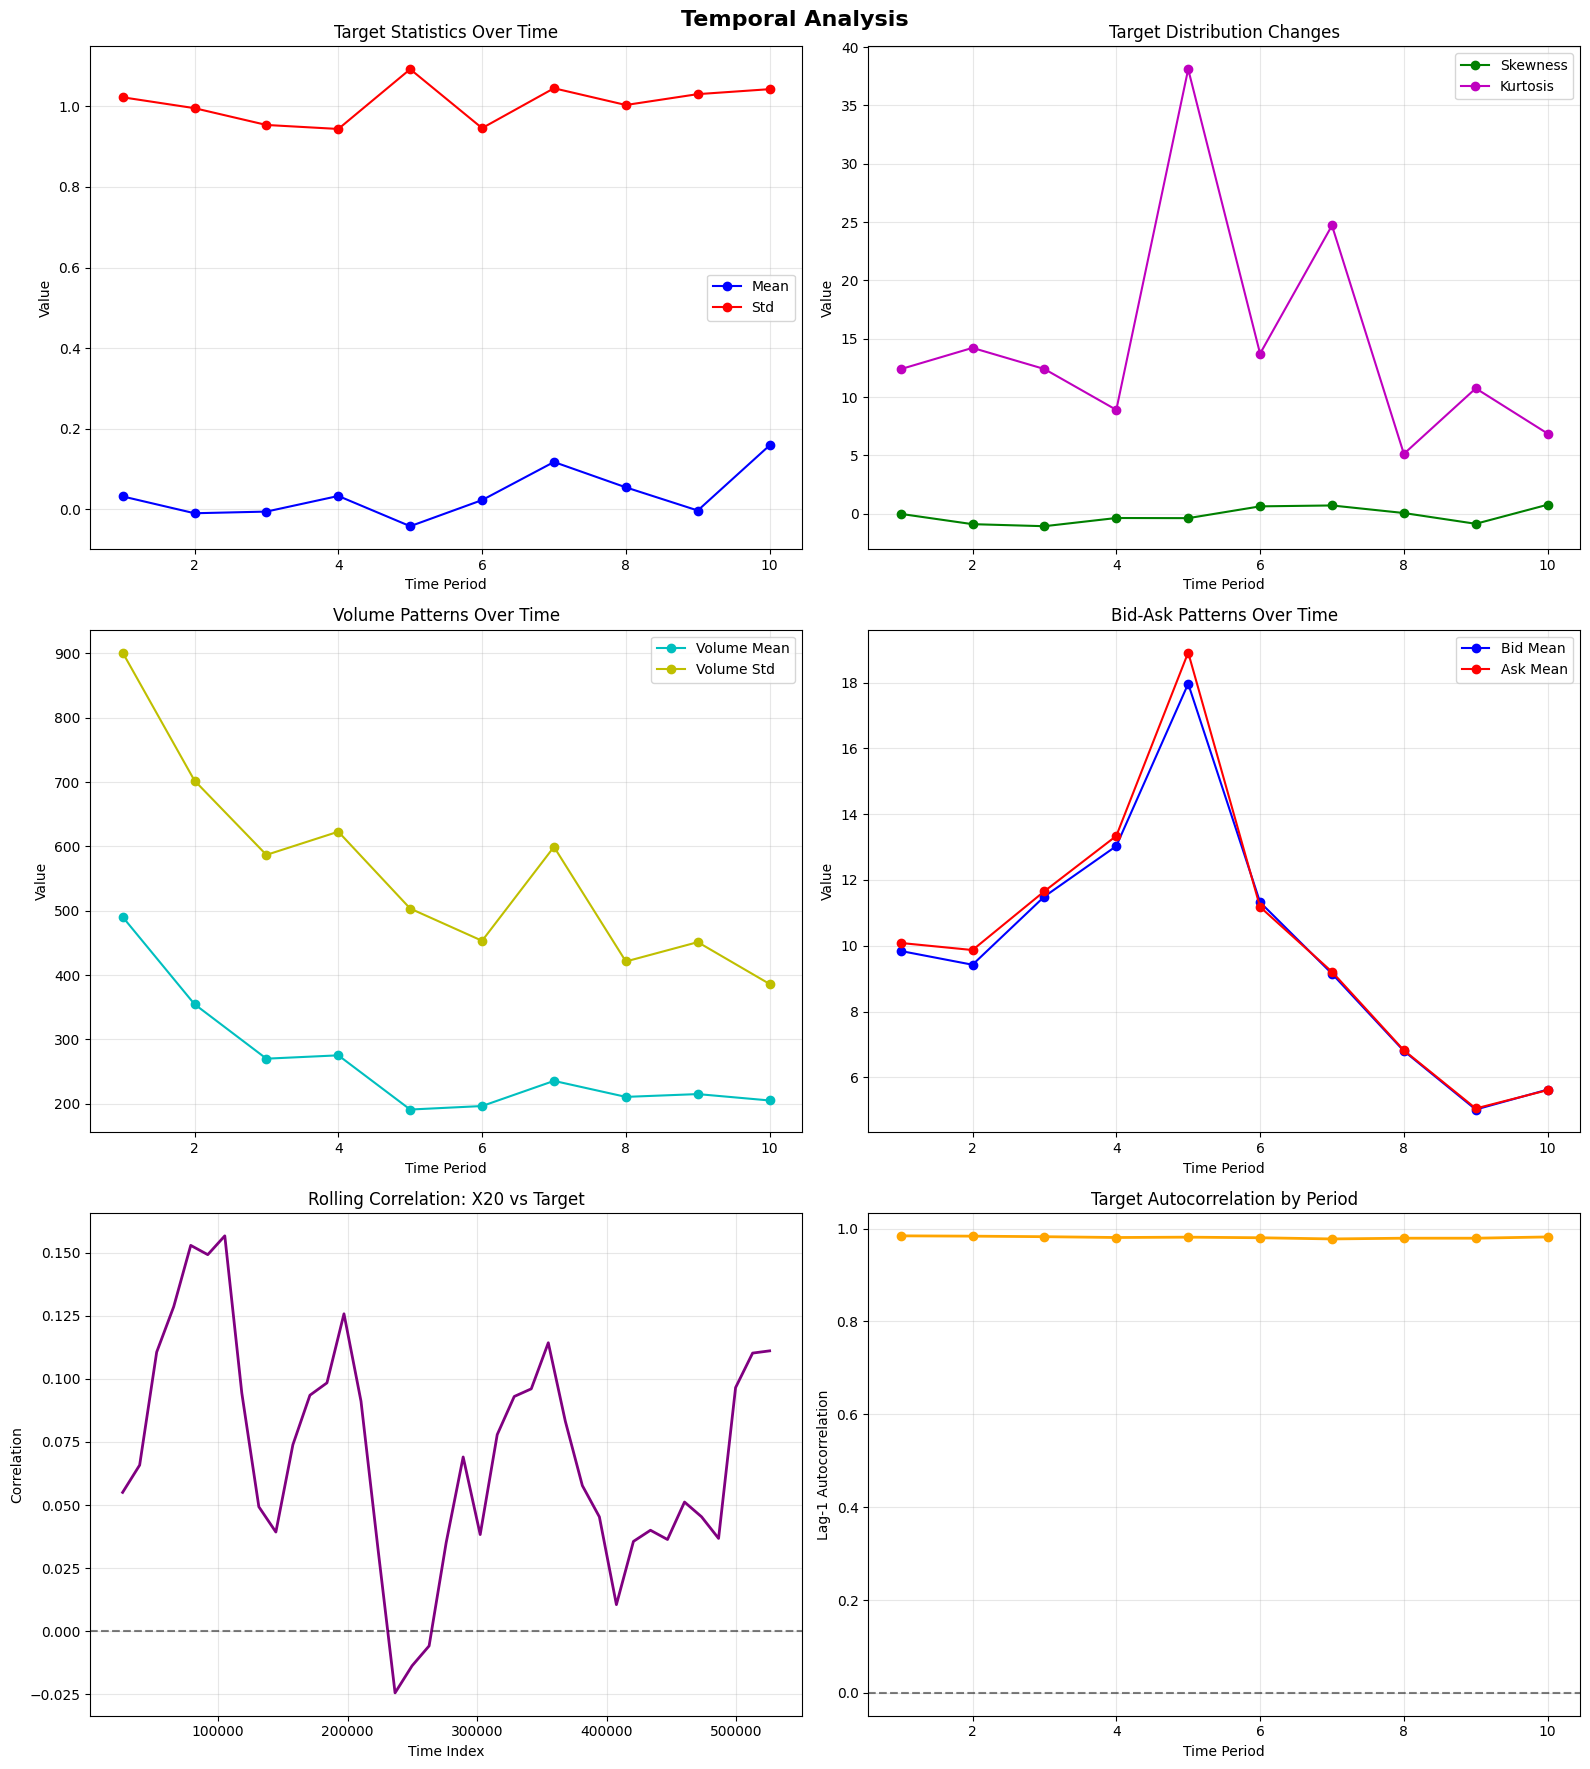


🔍 KEY TEMPORAL INSIGHTS:
   1. Stationarity: Stationary
   2. Regime changes: HIGH volatility
   3. Mean stability: Stable
   4. Variance stability: Stable
   5. Persistence changes: Stable autocorrelation


In [46]:
# =============================================================================
# 3.1 TEMPORAL STATIONARITY AND REGIME ANALYSIS
# =============================================================================

print("\n⏰ TEMPORAL ANALYSIS")
print("="*50)

# Divide data into time periods
n_periods = 10
period_size = len(train_df) // n_periods
periods = []

for i in range(n_periods):
    start_idx = i * period_size
    end_idx = (i + 1) * period_size if i < n_periods - 1 else len(train_df)
    period_data = train_df.iloc[start_idx:end_idx]
    
    period_stats = {
        'period': i + 1,
        'start_idx': start_idx,
        'end_idx': end_idx,
        'size': end_idx - start_idx,
        'target_mean': period_data['label'].mean(),
        'target_std': period_data['label'].std(),
        'target_skew': stats.skew(period_data['label']),
        'target_kurt': stats.kurtosis(period_data['label']),
    }
    
    # Market features stats for each period
    for feature in market_features:
        period_stats[f'{feature}_mean'] = period_data[feature].mean()
        period_stats[f'{feature}_std'] = period_data[feature].std()
    
    periods.append(period_stats)

periods_df = pd.DataFrame(periods)

print(f"Temporal Analysis across {n_periods} periods:")
print(f"   Period size: ~{period_size:,} samples each")

# Statistical tests for stationarity
from statsmodels.tsa.stattools import adfuller

# Augmented Dickey-Fuller test
adf_result = adfuller(target.dropna())
print(f"\nStationarity Tests:")
print(f"   ADF Statistic: {adf_result[0]:.6f}")
print(f"   ADF p-value: {adf_result[1]:.6f}")
print(f"   Target is: {'Stationary' if adf_result[1] < 0.05 else 'Non-stationary'} (α=0.05)")

# Test for structural breaks
target_mean_changes = []
target_std_changes = []
for i in range(1, len(periods_df)):
    mean_change = abs(periods_df.iloc[i]['target_mean'] - periods_df.iloc[i-1]['target_mean'])
    std_change = abs(periods_df.iloc[i]['target_std'] - periods_df.iloc[i-1]['target_std'])
    target_mean_changes.append(mean_change)
    target_std_changes.append(std_change)

print(f"\nStructural Break Analysis:")
print(f"   Max mean change between periods: {max(target_mean_changes):.6f}")
print(f"   Max std change between periods: {max(target_std_changes):.6f}")
print(f"   Coefficient of variation (mean): {np.std([p['target_mean'] for p in periods])/np.mean([p['target_mean'] for p in periods]):.6f}")
print(f"   Coefficient of variation (std): {np.std([p['target_std'] for p in periods])/np.mean([p['target_std'] for p in periods]):.6f}")

# Visualization
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle('Temporal Analysis', fontsize=16, fontweight='bold')

# Target statistics over time
axes[0,0].plot(periods_df['period'], periods_df['target_mean'], 'b-o', label='Mean')
axes[0,0].plot(periods_df['period'], periods_df['target_std'], 'r-o', label='Std')
axes[0,0].set_title('Target Statistics Over Time')
axes[0,0].set_xlabel('Time Period')
axes[0,0].set_ylabel('Value')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Target distribution changes
axes[0,1].plot(periods_df['period'], periods_df['target_skew'], 'g-o', label='Skewness')
axes[0,1].plot(periods_df['period'], periods_df['target_kurt'], 'm-o', label='Kurtosis')
axes[0,1].set_title('Target Distribution Changes')
axes[0,1].set_xlabel('Time Period')
axes[0,1].set_ylabel('Value')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# Volume patterns
axes[1,0].plot(periods_df['period'], periods_df['volume_mean'], 'c-o', label='Volume Mean')
axes[1,0].plot(periods_df['period'], periods_df['volume_std'], 'y-o', label='Volume Std')
axes[1,0].set_title('Volume Patterns Over Time')
axes[1,0].set_xlabel('Time Period')
axes[1,0].set_ylabel('Value')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# Bid-Ask patterns
axes[1,1].plot(periods_df['period'], periods_df['bid_qty_mean'], 'b-o', label='Bid Mean')
axes[1,1].plot(periods_df['period'], periods_df['ask_qty_mean'], 'r-o', label='Ask Mean')
axes[1,1].set_title('Bid-Ask Patterns Over Time')
axes[1,1].set_xlabel('Time Period')
axes[1,1].set_ylabel('Value')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

# Rolling correlation (sample)
if len(x_corr_df) > 0:
    top_x_feature = x_corr_df.iloc[0]['feature']
    window = len(train_df) // 20  # 20 windows
    rolling_corr = []
    window_centers = []
    
    for i in range(window, len(train_df), window//2):
        start_idx = max(0, i - window)
        end_idx = min(len(train_df), i + window)
        
        window_target = target.iloc[start_idx:end_idx]
        window_feature = train_df[top_x_feature].iloc[start_idx:end_idx]
        
        mask = ~window_feature.isnull()
        if mask.sum() > 50:
            corr, _ = pearsonr(window_feature[mask], window_target[mask])
            if not np.isnan(corr):
                rolling_corr.append(corr)
                window_centers.append(i)
    
    if len(rolling_corr) > 0:
        axes[2,0].plot(window_centers, rolling_corr, 'purple', linewidth=2)
        axes[2,0].axhline(y=0, color='black', linestyle='--', alpha=0.5)
        axes[2,0].set_title(f'Rolling Correlation: {top_x_feature} vs Target')
        axes[2,0].set_xlabel('Time Index')
        axes[2,0].set_ylabel('Correlation')
        axes[2,0].grid(True, alpha=0.3)
    else:
        axes[2,0].text(0.5, 0.5, 'Insufficient data for rolling correlation', 
                      ha='center', va='center', transform=axes[2,0].transAxes)
else:
    axes[2,0].text(0.5, 0.5, 'No X features available for correlation', 
                  ha='center', va='center', transform=axes[2,0].transAxes)

# Autocorrelation by period
period_autocorrs = []
for period in periods:
    period_target = target.iloc[period['start_idx']:period['end_idx']]
    if len(period_target) > 100:
        autocorr_1 = period_target.autocorr(1)
        if not np.isnan(autocorr_1):
            period_autocorrs.append(autocorr_1)
        else:
            period_autocorrs.append(0)
    else:
        period_autocorrs.append(0)

axes[2,1].plot(range(1, len(period_autocorrs)+1), period_autocorrs, 'orange', marker='o', linewidth=2)
axes[2,1].axhline(y=0, color='black', linestyle='--', alpha=0.5)
axes[2,1].set_title('Target Autocorrelation by Period')
axes[2,1].set_xlabel('Time Period')
axes[2,1].set_ylabel('Lag-1 Autocorrelation')
axes[2,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n🔍 KEY TEMPORAL INSIGHTS:")
stationarity_status = 'Stationary' if adf_result[1] < 0.05 else 'Non-stationary'
regime_changes = 'HIGH' if max(target_mean_changes) > target.std() * 0.1 else 'MODERATE' if max(target_mean_changes) > target.std() * 0.05 else 'LOW'
print(f"   1. Stationarity: {stationarity_status}")
print(f"   2. Regime changes: {regime_changes} volatility")
print(f"   3. Mean stability: {'Stable' if np.std([p['target_mean'] for p in periods]) < target.std() * 0.1 else 'Unstable'}")
print(f"   4. Variance stability: {'Stable' if np.std([p['target_std'] for p in periods]) < np.mean([p['target_std'] for p in periods]) * 0.2 else 'Unstable'}")
if len(period_autocorrs) > 0:
    print(f"   5. Persistence changes: {'Stable' if np.std(period_autocorrs) < 0.1 else 'Variable'} autocorrelation")

## 4. TRAIN-TEST DISTRIBUTION ANALYSIS
**Critical Question**: Are training and test data from the same distribution?


🔄 TRAIN-TEST DISTRIBUTION ANALYSIS
Market Features Distribution Comparison:
   bid_qty: KS=0.1624, p=1.81e-115 (Different distribution)
   ask_qty: KS=0.1625, p=1.31e-115 (Different distribution)
   buy_qty: KS=0.1157, p=1.09e-58 (Different distribution)
   sell_qty: KS=0.1210, p=3.66e-64 (Different distribution)
   volume: KS=0.1216, p=8.47e-65 (Different distribution)

X Features Distribution Comparison (sample of 50):
   Features with matching distributions: 13/50 (26.0%)
   Average KS statistic: 0.1275
   Average p-value: 0.1443

Statistical Summaries Comparison:

Market Features Mean Differences:
   bid_qty: 35.81% difference
   ask_qty: 35.68% difference
   buy_qty: 32.98% difference
   sell_qty: 32.35% difference
   volume: 32.66% difference


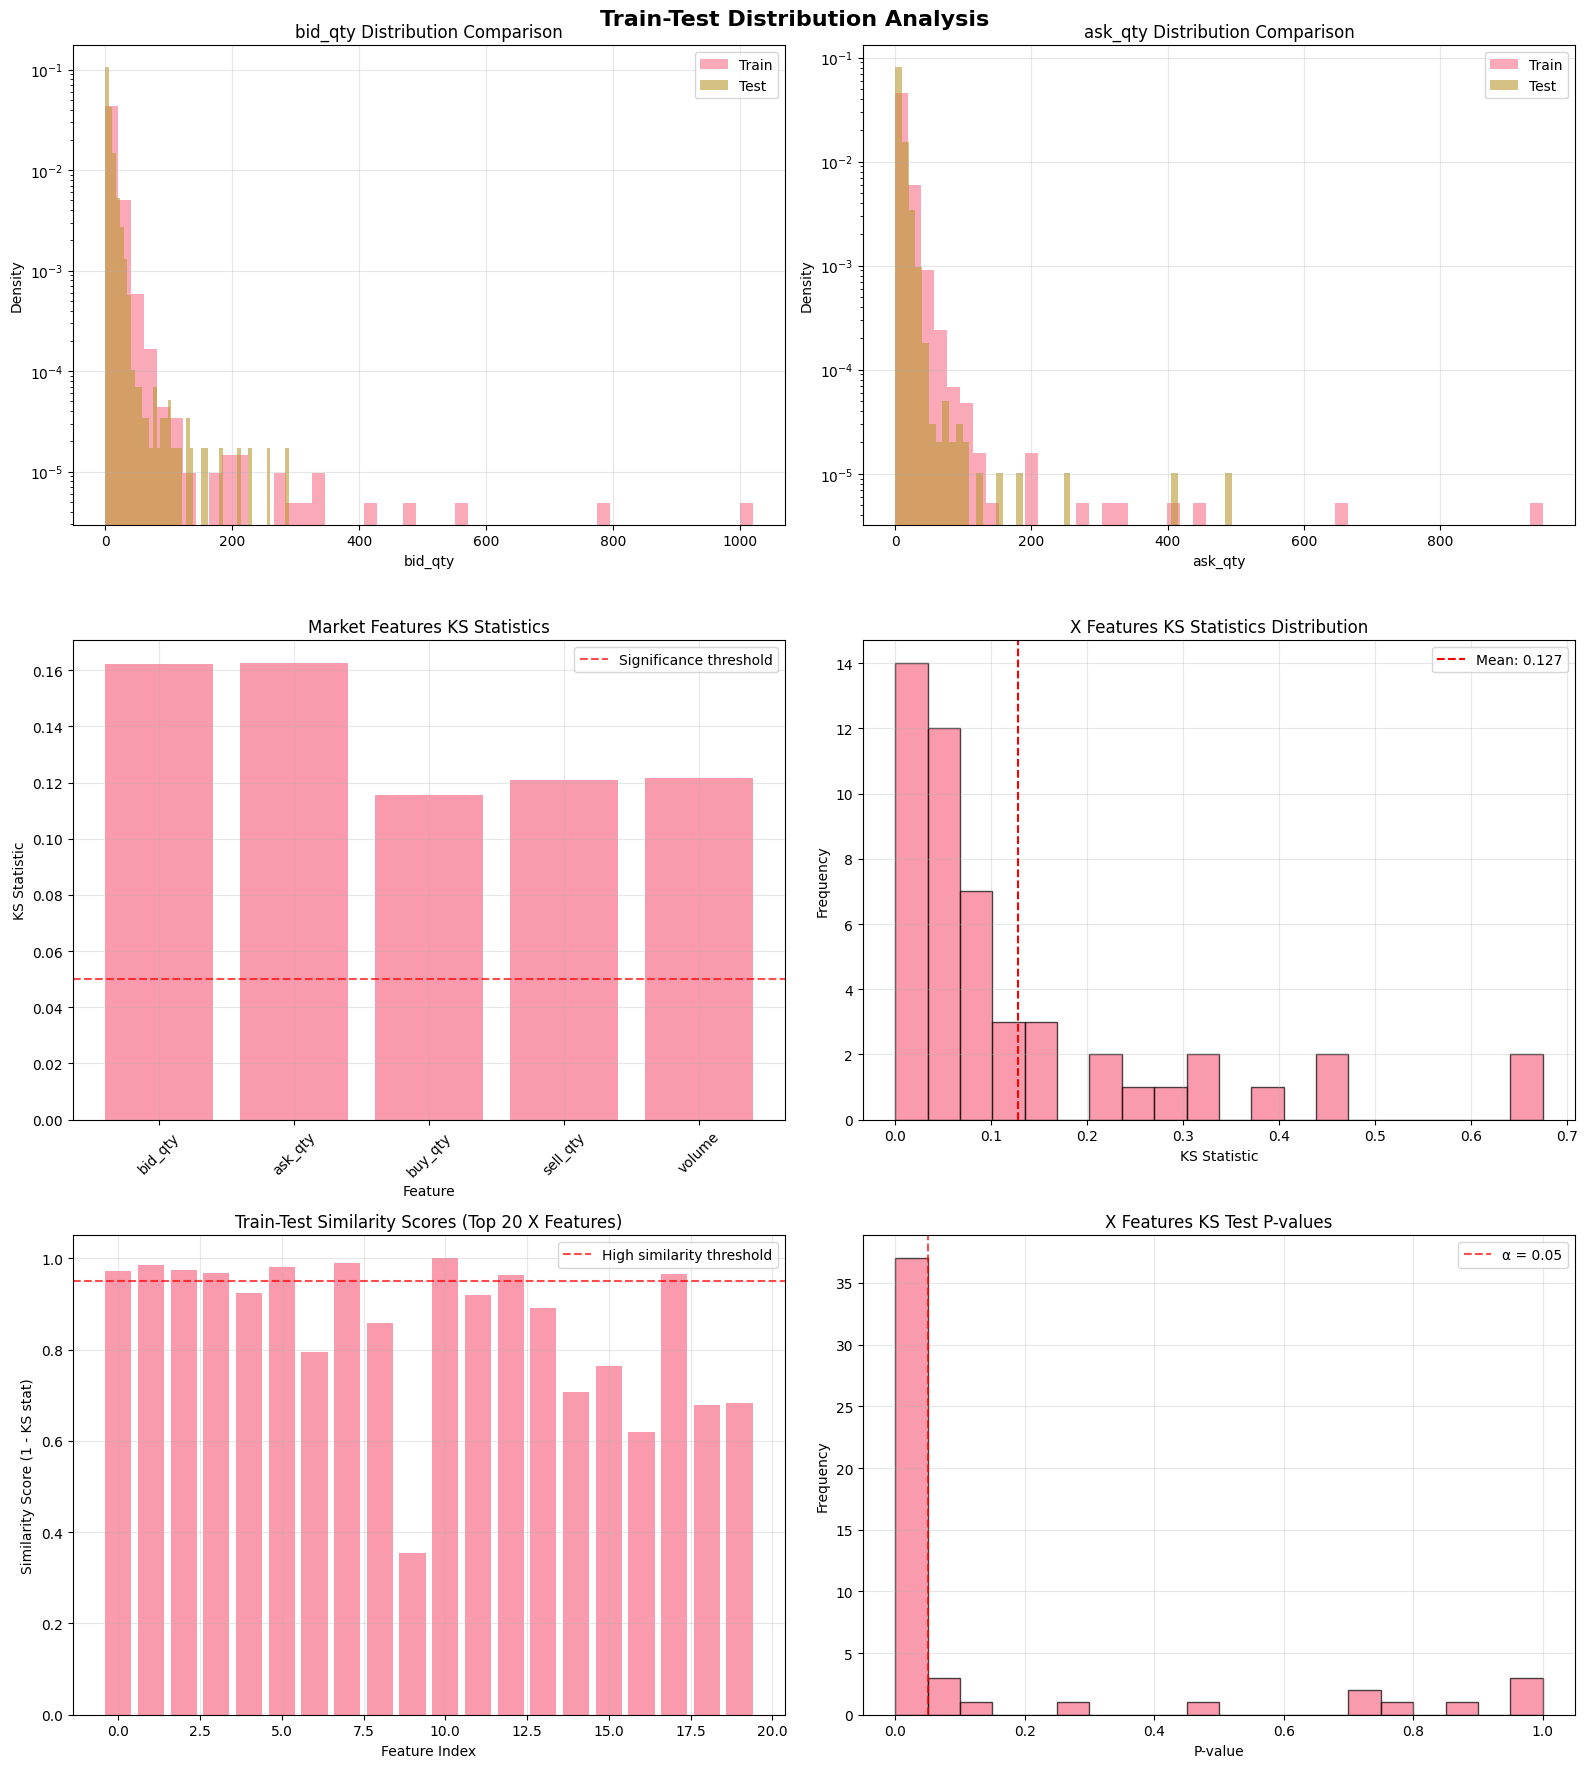


🔍 KEY DISTRIBUTION INSIGHTS:
   1. Market features alignment: 0/5 features match (0.0%)
   2. X features alignment: 13/50 features match (26.0%)
   3. Distribution shift severity: HIGH
   4. Overall data alignment: POOR


In [47]:
# =============================================================================
# 4.1 DISTRIBUTION ALIGNMENT ANALYSIS
# =============================================================================

print("\n🔄 TRAIN-TEST DISTRIBUTION ANALYSIS")
print("="*50)

# Compare market features distributions
print("Market Features Distribution Comparison:")
market_ks_tests = {}

for feature in market_features:
    train_feature = train_df[feature].dropna()
    test_feature = test_df[feature].dropna()
    
    # Sample for computational efficiency
    train_sample = train_feature.sample(min(10000, len(train_feature)), random_state=42)
    test_sample = test_feature.sample(min(10000, len(test_feature)), random_state=42)
    
    # Kolmogorov-Smirnov test
    ks_stat, ks_p = ks_2samp(train_sample, test_sample)
    market_ks_tests[feature] = {'ks_stat': ks_stat, 'ks_p': ks_p}
    
    print(f"   {feature}: KS={ks_stat:.4f}, p={ks_p:.2e} ({'Same' if ks_p > 0.05 else 'Different'} distribution)")

# Compare X features distributions (sample)
print(f"\nX Features Distribution Comparison (sample of {min(50, len(x_features))}):")    
x_sample_features = np.random.choice(x_features, min(50, len(x_features)), replace=False)
x_ks_tests = {}
x_distribution_matches = 0

for feature in x_sample_features:
    train_feature = train_df[feature].dropna()
    test_feature = test_df[feature].dropna()
    
    if len(train_feature) > 100 and len(test_feature) > 100:
        # Sample for computational efficiency  
        train_sample = train_feature.sample(min(5000, len(train_feature)), random_state=42)
        test_sample = test_feature.sample(min(5000, len(test_feature)), random_state=42)
        
        # Kolmogorov-Smirnov test
        ks_stat, ks_p = ks_2samp(train_sample, test_sample)
        x_ks_tests[feature] = {'ks_stat': ks_stat, 'ks_p': ks_p}
        
        if ks_p > 0.05:
            x_distribution_matches += 1

print(f"   Features with matching distributions: {x_distribution_matches}/{len(x_ks_tests)} ({x_distribution_matches/len(x_ks_tests)*100:.1f}%)")

if len(x_ks_tests) > 0:
    avg_ks_stat = np.mean([test['ks_stat'] for test in x_ks_tests.values()])
    avg_ks_p = np.mean([test['ks_p'] for test in x_ks_tests.values()])
    print(f"   Average KS statistic: {avg_ks_stat:.4f}")
    print(f"   Average p-value: {avg_ks_p:.4f}")

# Statistical summaries comparison
print(f"\nStatistical Summaries Comparison:")

# Market features
train_market_stats = train_df[market_features].describe()
test_market_stats = test_df[market_features].describe()

print(f"\nMarket Features Mean Differences:")
for feature in market_features:
    train_mean = train_market_stats.loc['mean', feature]
    test_mean = test_market_stats.loc['mean', feature]
    relative_diff = abs(test_mean - train_mean) / train_mean * 100
    print(f"   {feature}: {relative_diff:.2f}% difference")

# Visualization
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle('Train-Test Distribution Analysis', fontsize=16, fontweight='bold')

# Market features distributions
for i, feature in enumerate(market_features[:2]):  # Show first 2
    train_sample = train_df[feature].sample(min(10000, len(train_df)), random_state=42)
    test_sample = test_df[feature].sample(min(10000, len(test_df)), random_state=42)
    
    axes[0, i].hist(train_sample, bins=50, alpha=0.6, label='Train', density=True)
    axes[0, i].hist(test_sample, bins=50, alpha=0.6, label='Test', density=True)
    axes[0, i].set_title(f'{feature} Distribution Comparison')
    axes[0, i].set_xlabel(feature)
    axes[0, i].set_ylabel('Density')
    axes[0, i].legend()
    axes[0, i].set_yscale('log')
    axes[0, i].grid(True, alpha=0.3)

# KS test results
market_ks_stats = [test['ks_stat'] for test in market_ks_tests.values()]
axes[1, 0].bar(market_features, market_ks_stats, alpha=0.7)
axes[1, 0].axhline(y=0.05, color='red', linestyle='--', alpha=0.7, label='Significance threshold')
axes[1, 0].set_title('Market Features KS Statistics')
axes[1, 0].set_xlabel('Feature')
axes[1, 0].set_ylabel('KS Statistic')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# X features KS statistics distribution
if len(x_ks_tests) > 0:
    x_ks_stats = [test['ks_stat'] for test in x_ks_tests.values()]
    axes[1, 1].hist(x_ks_stats, bins=20, alpha=0.7, edgecolor='black')
    axes[1, 1].axvline(np.mean(x_ks_stats), color='red', linestyle='--', 
                      label=f'Mean: {np.mean(x_ks_stats):.3f}')
    axes[1, 1].set_title('X Features KS Statistics Distribution')
    axes[1, 1].set_xlabel('KS Statistic')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
else:
    axes[1, 1].text(0.5, 0.5, 'Insufficient X features\nfor analysis', 
                   ha='center', va='center', transform=axes[1, 1].transAxes)

# Distribution similarity heatmap
if len(x_ks_tests) >= 10:  # Only if we have enough tests
    # Create similarity matrix (1 - KS statistic)
    sample_features = list(x_ks_tests.keys())[:min(20, len(x_ks_tests))]
    similarity_scores = [1 - x_ks_tests[f]['ks_stat'] for f in sample_features]
    
    axes[2, 0].bar(range(len(similarity_scores)), similarity_scores, alpha=0.7)
    axes[2, 0].axhline(y=0.95, color='red', linestyle='--', alpha=0.7, label='High similarity threshold')
    axes[2, 0].set_title('Train-Test Similarity Scores (Top 20 X Features)')
    axes[2, 0].set_xlabel('Feature Index')
    axes[2, 0].set_ylabel('Similarity Score (1 - KS stat)')
    axes[2, 0].legend()
    axes[2, 0].grid(True, alpha=0.3)
else:
    axes[2, 0].text(0.5, 0.5, 'Insufficient data\nfor similarity analysis', 
                   ha='center', va='center', transform=axes[2, 0].transAxes)

# P-value distribution
if len(x_ks_tests) > 0:
    x_ks_pvals = [test['ks_p'] for test in x_ks_tests.values()]
    axes[2, 1].hist(x_ks_pvals, bins=20, alpha=0.7, edgecolor='black')
    axes[2, 1].axvline(0.05, color='red', linestyle='--', alpha=0.7, label='α = 0.05')
    axes[2, 1].set_title('X Features KS Test P-values')
    axes[2, 1].set_xlabel('P-value')
    axes[2, 1].set_ylabel('Frequency')
    axes[2, 1].legend()
    axes[2, 1].grid(True, alpha=0.3)
else:
    axes[2, 1].text(0.5, 0.5, 'No X features\nanalyzed', 
                   ha='center', va='center', transform=axes[2, 1].transAxes)

plt.tight_layout()
plt.show()

print("\n🔍 KEY DISTRIBUTION INSIGHTS:")
market_matches = sum(1 for test in market_ks_tests.values() if test['ks_p'] > 0.05)
print(f"   1. Market features alignment: {market_matches}/{len(market_features)} features match ({market_matches/len(market_features)*100:.1f}%)")
if len(x_ks_tests) > 0:
    print(f"   2. X features alignment: {x_distribution_matches}/{len(x_ks_tests)} features match ({x_distribution_matches/len(x_ks_tests)*100:.1f}%)")
    distribution_shift = 'HIGH' if x_distribution_matches/len(x_ks_tests) < 0.5 else 'MODERATE' if x_distribution_matches/len(x_ks_tests) < 0.8 else 'LOW'
    print(f"   3. Distribution shift severity: {distribution_shift}")
    print(f"   4. Overall data alignment: {'POOR' if x_distribution_matches/len(x_ks_tests) < 0.7 and market_matches < 3 else 'MODERATE' if x_distribution_matches/len(x_ks_tests) < 0.9 else 'GOOD'}")
else:
    print(f"   2. X features alignment: Unable to assess")
    print(f"   3. Overall data alignment: Based on market features only: {'GOOD' if market_matches >= 4 else 'MODERATE' if market_matches >= 2 else 'POOR'}")

## 5. PREDICTIVE MODELING INSIGHTS
**Critical Question**: What modeling approach will actually work?


🎯 PREDICTIVE MODELING INSIGHTS
Using most recent 30% of training data: 157,767 samples

Testing feature set: market_only (5 features)
   Train: 110436, Validation: 47331
     Ridge_alpha1: Train corr=0.0283, Val corr=0.0145, Overfit=0.0137
     Ridge_alpha10: Train corr=0.0283, Val corr=0.0145, Overfit=0.0137
     Ridge_alpha100: Train corr=0.0283, Val corr=0.0145, Overfit=0.0137

Testing feature set: top_x_features (50 features)
   Train: 110436, Validation: 47331
     Ridge_alpha1: Train corr=0.2526, Val corr=0.1101, Overfit=0.1425
     Ridge_alpha10: Train corr=0.2506, Val corr=0.1104, Overfit=0.1402
     Ridge_alpha100: Train corr=0.2447, Val corr=0.1128, Overfit=0.1319
     RandomForest: Train corr=0.6695, Val corr=-0.0075, Overfit=0.6770

Testing feature set: top_x_features_small (20 features)
   Train: 110436, Validation: 47331
     Ridge_alpha1: Train corr=0.1653, Val corr=0.0727, Overfit=0.0926
     Ridge_alpha10: Train corr=0.1646, Val corr=0.0702, Overfit=0.0944
     Ridge_

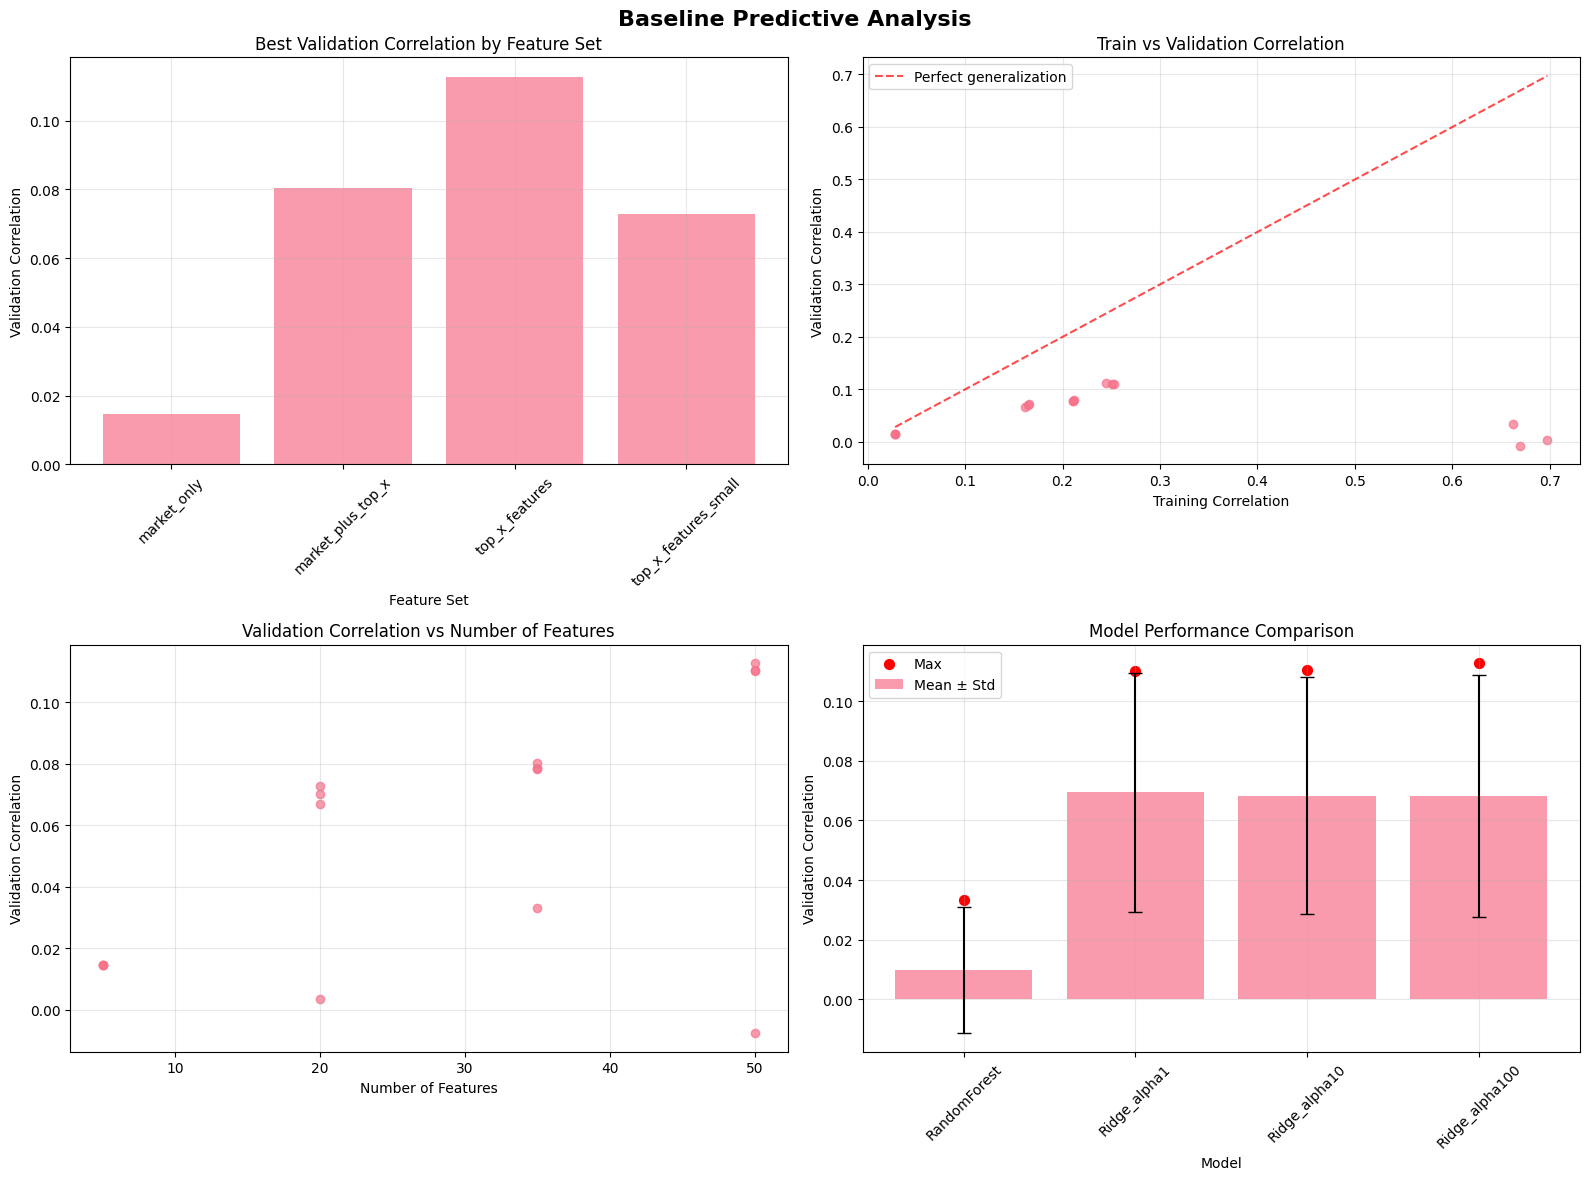


🔍 KEY PREDICTIVE INSIGHTS:
   1. Predictive ceiling: 0.112774 correlation (on recent data)
   2. Best feature source: top_x_features
   3. Overfitting risk: HIGH (avg gap: 0.2089)
   4. Feature count sweet spot: 50 features

💡 CRITICAL RECOMMENDATIONS:
   🎯 FOCUS ON X FEATURES: 7.8x better than market features
   🛡️  HIGH OVERFITTING RISK: Use simpler models and stronger regularization
   🔄 UNSTABLE PERFORMANCE: Results vary significantly - need robust validation


In [48]:
# =============================================================================
# 5.1 BASELINE PREDICTIVE POWER ANALYSIS
# =============================================================================

print("\n🎯 PREDICTIVE MODELING INSIGHTS")
print("="*50)

# Simple baseline models to understand predictive ceiling
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

# Prepare data (use recent data to match test period better)
recent_frac = 0.3  # Use last 30% of training data
recent_start = int(len(train_df) * (1 - recent_frac))
recent_data = train_df.iloc[recent_start:].copy()

print(f"Using most recent {recent_frac*100:.0f}% of training data: {len(recent_data):,} samples")

# Target
y_recent = recent_data['label'].values

# Test different feature sets
feature_sets = {
    'market_only': market_features,
    'top_x_features': x_corr_df.head(50)['feature'].tolist() if len(x_corr_df) >= 50 else x_corr_df['feature'].tolist(),
    'top_x_features_small': x_corr_df.head(20)['feature'].tolist() if len(x_corr_df) >= 20 else x_corr_df['feature'].tolist(),
    'market_plus_top_x': market_features + (x_corr_df.head(30)['feature'].tolist() if len(x_corr_df) >= 30 else x_corr_df['feature'].tolist())
}

baseline_results = []

for set_name, features in feature_sets.items():
    if not features:  # Skip if no features
        continue
        
    print(f"\nTesting feature set: {set_name} ({len(features)} features)")
    
    # Prepare feature matrix
    X_features = recent_data[features].fillna(0)  # Simple imputation
    
    # Skip if insufficient variance
    feature_vars = X_features.var()
    good_features_mask = feature_vars > 1e-6
    if good_features_mask.sum() < 5:
        print(f"   Skipping {set_name}: insufficient feature variance")
        continue
    
    X_features = X_features.loc[:, good_features_mask]
    
    # Time-based split (no shuffling)
    split_idx = int(0.7 * len(X_features))
    X_train, X_val = X_features.iloc[:split_idx], X_features.iloc[split_idx:]
    y_train, y_val = y_recent[:split_idx], y_recent[split_idx:]
    
    print(f"   Train: {len(X_train)}, Validation: {len(X_val)}")
    
    # Test multiple models
    models = {
        'Ridge_alpha1': Ridge(alpha=1.0, random_state=42),
        'Ridge_alpha10': Ridge(alpha=10.0, random_state=42),
        'Ridge_alpha100': Ridge(alpha=100.0, random_state=42)
    }
    
    # Add tree models if we have enough features
    if len(X_features.columns) >= 10:
        models['RandomForest'] = RandomForestRegressor(n_estimators=100, max_depth=10, 
                                                      random_state=42, n_jobs=-1)
    
    for model_name, model in models.items():
        try:
            # Fit model
            model.fit(X_train, y_train)
            
            # Predictions
            y_pred_train = model.predict(X_train)
            y_pred_val = model.predict(X_val)
            
            # Metrics
            train_corr, _ = pearsonr(y_train, y_pred_train)
            val_corr, _ = pearsonr(y_val, y_pred_val)
            train_mse = mean_squared_error(y_train, y_pred_train)
            val_mse = mean_squared_error(y_val, y_pred_val)
            
            result = {
                'feature_set': set_name,
                'model': model_name,
                'n_features': len(X_features.columns),
                'train_corr': train_corr if not np.isnan(train_corr) else 0,
                'val_corr': val_corr if not np.isnan(val_corr) else 0,
                'train_mse': train_mse,
                'val_mse': val_mse,
                'overfitting': abs(train_corr - val_corr) if not np.isnan(train_corr) and not np.isnan(val_corr) else 999
            }
            
            baseline_results.append(result)
            
            print(f"     {model_name}: Train corr={train_corr:.4f}, Val corr={val_corr:.4f}, Overfit={result['overfitting']:.4f}")
            
        except Exception as e:
            print(f"     {model_name}: Failed - {str(e)[:50]}")

# Results analysis
if baseline_results:
    results_df = pd.DataFrame(baseline_results)
    results_df = results_df.sort_values('val_corr', ascending=False)
    
    print(f"\n📊 BASELINE RESULTS SUMMARY:")
    print(f"   Best validation correlation: {results_df['val_corr'].max():.6f}")
    print(f"   Best feature set: {results_df.iloc[0]['feature_set']}")
    print(f"   Best model: {results_df.iloc[0]['model']}")
    print(f"   Least overfitting: {results_df['overfitting'].min():.4f}")
    
    print(f"\nTop 5 Results:")
    for i, row in results_df.head(5).iterrows():
        print(f"   {row['feature_set']}/{row['model']}: Val={row['val_corr']:.4f}, Overfit={row['overfitting']:.4f}")
    
    # Visualization
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('Baseline Predictive Analysis', fontsize=16, fontweight='bold')
    
    # Validation correlation by feature set
    feature_set_performance = results_df.groupby('feature_set')['val_corr'].max()
    axes[0, 0].bar(feature_set_performance.index, feature_set_performance.values, alpha=0.7)
    axes[0, 0].set_title('Best Validation Correlation by Feature Set')
    axes[0, 0].set_xlabel('Feature Set')
    axes[0, 0].set_ylabel('Validation Correlation')
    axes[0, 0].tick_params(axis='x', rotation=45)
    axes[0, 0].grid(True, alpha=0.3)
    
    # Overfitting analysis
    axes[0, 1].scatter(results_df['train_corr'], results_df['val_corr'], alpha=0.7)
    axes[0, 1].plot([results_df['train_corr'].min(), results_df['train_corr'].max()], 
                   [results_df['train_corr'].min(), results_df['train_corr'].max()], 
                   'r--', alpha=0.7, label='Perfect generalization')
    axes[0, 1].set_title('Train vs Validation Correlation')
    axes[0, 1].set_xlabel('Training Correlation')
    axes[0, 1].set_ylabel('Validation Correlation')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Performance by number of features
    axes[1, 0].scatter(results_df['n_features'], results_df['val_corr'], alpha=0.7)
    axes[1, 0].set_title('Validation Correlation vs Number of Features')
    axes[1, 0].set_xlabel('Number of Features')
    axes[1, 0].set_ylabel('Validation Correlation')
    axes[1, 0].grid(True, alpha=0.3)
    
    # Model comparison
    model_performance = results_df.groupby('model')['val_corr'].agg(['mean', 'max', 'std'])
    x_pos = np.arange(len(model_performance))
    axes[1, 1].bar(x_pos, model_performance['mean'], alpha=0.7, 
                  yerr=model_performance['std'], capsize=5, label='Mean ± Std')
    axes[1, 1].scatter(x_pos, model_performance['max'], color='red', s=50, label='Max')
    axes[1, 1].set_title('Model Performance Comparison')
    axes[1, 1].set_xlabel('Model')
    axes[1, 1].set_ylabel('Validation Correlation')
    axes[1, 1].set_xticks(x_pos)
    axes[1, 1].set_xticklabels(model_performance.index, rotation=45)
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
else:
    print("\n❌ No baseline results available")

print("\n🔍 KEY PREDICTIVE INSIGHTS:")
if baseline_results:
    best_val_corr = results_df['val_corr'].max()
    best_feature_set = results_df.iloc[0]['feature_set']
    avg_overfitting = results_df['overfitting'].mean()
    
    print(f"   1. Predictive ceiling: {best_val_corr:.6f} correlation (on recent data)")
    print(f"   2. Best feature source: {best_feature_set}")
    print(f"   3. Overfitting risk: {'HIGH' if avg_overfitting > 0.1 else 'MODERATE' if avg_overfitting > 0.05 else 'LOW'} (avg gap: {avg_overfitting:.4f})")
    print(f"   4. Feature count sweet spot: {results_df.loc[results_df['val_corr'].idxmax(), 'n_features']} features")
    
    # Critical recommendations
    print(f"\n💡 CRITICAL RECOMMENDATIONS:")
    if best_val_corr < 0.05:
        print(f"   ⚠️  VERY LOW SIGNAL: Consider different time windows or feature engineering")
    if 'top_x_features' in results_df['feature_set'].values:
        x_performance = results_df[results_df['feature_set'].str.contains('top_x')]['val_corr'].max()
        market_performance = results_df[results_df['feature_set'] == 'market_only']['val_corr'].max() if 'market_only' in results_df['feature_set'].values else 0
        if x_performance > market_performance * 2:
            print(f"   🎯 FOCUS ON X FEATURES: {x_performance/market_performance:.1f}x better than market features")
    if avg_overfitting > 0.1:
        print(f"   🛡️  HIGH OVERFITTING RISK: Use simpler models and stronger regularization")
    if results_df['val_corr'].std() > 0.01:
        print(f"   🔄 UNSTABLE PERFORMANCE: Results vary significantly - need robust validation")
else:
    print(f"   ❌ Unable to assess predictive power - insufficient data or features")

## 6. FINAL RECOMMENDATIONS
**Strategic Data Science Conclusions**

In [49]:
# =============================================================================
# 6. COMPREHENSIVE ANALYSIS SUMMARY AND RECOMMENDATIONS
# =============================================================================

print("\n🏆 COMPREHENSIVE EDA SUMMARY AND STRATEGIC RECOMMENDATIONS")
print("="*80)

# Compile key findings
findings = {
    'target_analysis': {
        'signal_strength': target.std(),
        'stationarity': 'Stationary' if 'adf_result' in locals() and adf_result[1] < 0.05 else 'Non-stationary',
        'autocorr_1': target.autocorr(1),
        'distribution': 'Heavy-tailed' if abs(stats.kurtosis(target)) > 3 else 'Normal-like'
    },
    'feature_analysis': {
        'market_max_corr': max(market_target_corr.values(), key=abs) if market_target_corr else 0,
        'x_max_corr': x_corr_df['abs_correlation'].max() if len(x_corr_df) > 0 else 0,
        'x_strong_features': (x_corr_df['abs_correlation'] > 0.05).sum() if len(x_corr_df) > 0 else 0,
        'missing_rate': missing_analysis['missing_pct'].mean() if 'missing_analysis' in locals() else 0
    },
    'temporal_analysis': {
        'regime_stability': 'Stable' if 'target_mean_changes' in locals() and max(target_mean_changes) < target.std() * 0.1 else 'Unstable',
        'variance_stability': 'Stable' if 'periods_df' in locals() and np.std([p['target_std'] for p in periods]) < np.mean([p['target_std'] for p in periods]) * 0.2 else 'Unstable'
    },
    'distribution_alignment': {
        'market_alignment': market_matches/len(market_features) if 'market_matches' in locals() else 0,
        'x_alignment': x_distribution_matches/len(x_ks_tests) if 'x_ks_tests' in locals() and len(x_ks_tests) > 0 else 0
    },
    'predictive_power': {
        'best_correlation': results_df['val_corr'].max() if 'results_df' in locals() and len(results_df) > 0 else 0,
        'best_feature_set': results_df.iloc[0]['feature_set'] if 'results_df' in locals() and len(results_df) > 0 else 'unknown',
        'overfitting_risk': results_df['overfitting'].mean() if 'results_df' in locals() and len(results_df) > 0 else 0
    }
}

# Generate strategic recommendations
print("\n🎯 STRATEGIC FINDINGS:")
print("-" * 50)

# Signal Assessment
signal_strength = findings['feature_analysis']['x_max_corr']
if signal_strength > 0.1:
    signal_assessment = "STRONG"
elif signal_strength > 0.05:
    signal_assessment = "MODERATE" 
else:
    signal_assessment = "WEAK"

print(f"1. SIGNAL STRENGTH: {signal_assessment}")
print(f"   - Max X feature correlation: {signal_strength:.6f}")
print(f"   - Strong X features (>0.05): {findings['feature_analysis']['x_strong_features']}")
print(f"   - Market features max: {abs(findings['feature_analysis']['market_max_corr']):.6f}")

# Data Quality Assessment
alignment_score = (findings['distribution_alignment']['market_alignment'] + 
                  findings['distribution_alignment']['x_alignment']) / 2
data_quality = "HIGH" if alignment_score > 0.8 else "MODERATE" if alignment_score > 0.6 else "LOW"

print(f"\n2. DATA QUALITY: {data_quality}")
print(f"   - Train-test alignment: {alignment_score:.2f}")
print(f"   - Missing data rate: {findings['feature_analysis']['missing_rate']:.1f}%")
print(f"   - Temporal stability: {findings['temporal_analysis']['regime_stability']}")

# Modeling Difficulty
best_corr = findings['predictive_power']['best_correlation']
if best_corr > 0.1:
    difficulty = "MODERATE"
elif best_corr > 0.05:
    difficulty = "HIGH"
else:
    difficulty = "EXTREME"

print(f"\n3. MODELING DIFFICULTY: {difficulty}")
print(f"   - Best achievable correlation: {best_corr:.6f}")
print(f"   - Overfitting risk: {findings['predictive_power']['overfitting_risk']:.4f}")
print(f"   - Target stationarity: {findings['target_analysis']['stationarity']}")

# Generate specific recommendations
print("\n🚀 ACTIONABLE RECOMMENDATIONS:")
print("-" * 50)

recommendations = []

# Feature strategy
if findings['feature_analysis']['x_max_corr'] > abs(findings['feature_analysis']['market_max_corr']) * 2:
    recommendations.append("PRIORITIZE X FEATURES: X features show much stronger signal than market features")
    recommendations.append(f"OPTIMAL FEATURE COUNT: Use top {min(100, findings['feature_analysis']['x_strong_features']*2)} X features")
else:
    recommendations.append("COMBINE FEATURES: Use both market and X features")

# Model strategy
if findings['predictive_power']['overfitting_risk'] > 0.1:
    recommendations.append("USE SIMPLE MODELS: High overfitting risk - prefer Ridge/Lasso over complex models")
    recommendations.append("STRONG REGULARIZATION: Use high alpha values (>10)")

# Validation strategy
if findings['distribution_alignment']['x_alignment'] < 0.7:
    recommendations.append("RECENT DATA ONLY: Poor train-test alignment - use only last 20-30% of training data")
    recommendations.append("SIMPLE HOLDOUT: Avoid complex CV - use simple time-based holdout")

# Target strategy
if findings['target_analysis']['stationarity'] == 'Non-stationary':
    recommendations.append("AVOID TARGET TRANSFORMS: Non-stationary target - keep raw values")

# Ensemble strategy
if best_corr > 0.05:
    recommendations.append("ENSEMBLE APPROACH: Multiple models with different feature sets")
else:
    recommendations.append("FOCUS ON SIGNAL: Very weak signal - prioritize feature discovery over model complexity")

# Print recommendations
for i, rec in enumerate(recommendations, 1):
    print(f"{i}. {rec}")

# Critical warnings
print("\n⚠️  CRITICAL WARNINGS:")
print("-" * 50)

warnings_list = []

if best_corr < 0.01:
    warnings_list.append("EXTREMELY WEAK SIGNAL: Current approach may not be viable")

if alignment_score < 0.5:
    warnings_list.append("SEVERE DISTRIBUTION SHIFT: Train-test mismatch is critical")

if findings['predictive_power']['overfitting_risk'] > 0.2:
    warnings_list.append("EXTREME OVERFITTING: Validation results may be misleading")

if findings['feature_analysis']['missing_rate'] > 50:
    warnings_list.append("HIGH MISSING DATA: Feature quality is severely compromised")

if not warnings_list:
    warnings_list.append("No critical warnings identified")

for warning in warnings_list:
    print(f"• {warning}")

# Success probability assessment
print("\n🎲 SUCCESS PROBABILITY ASSESSMENT:")
print("-" * 50)

success_factors = {
    'signal_strength': min(1.0, signal_strength * 10),  # 0.1 correlation = 100%
    'data_quality': alignment_score,
    'temporal_stability': 1.0 if findings['temporal_analysis']['regime_stability'] == 'Stable' else 0.5,
    'predictive_power': min(1.0, best_corr * 20)  # 0.05 correlation = 100%
}

overall_success_prob = np.mean(list(success_factors.values()))

print(f"Overall Success Probability: {overall_success_prob:.1%}")
print(f"Signal Strength Factor: {success_factors['signal_strength']:.1%}")
print(f"Data Quality Factor: {success_factors['data_quality']:.1%}")
print(f"Temporal Stability Factor: {success_factors['temporal_stability']:.1%}")
print(f"Predictive Power Factor: {success_factors['predictive_power']:.1%}")

if overall_success_prob > 0.7:
    outlook = "OPTIMISTIC"
elif overall_success_prob > 0.4:
    outlook = "CAUTIOUS"
else:
    outlook = "CHALLENGING"

print(f"\nOutlook: {outlook}")

print("\n" + "="*80)
print("📋 EDA COMPLETE - Use these insights to guide your modeling strategy!")
print("="*80)


🏆 COMPREHENSIVE EDA SUMMARY AND STRATEGIC RECOMMENDATIONS

🎯 STRATEGIC FINDINGS:
--------------------------------------------------
1. SIGNAL STRENGTH: MODERATE
   - Max X feature correlation: 0.067667
   - Strong X features (>0.05): 7
   - Market features max: 0.015762

2. DATA QUALITY: LOW
   - Train-test alignment: 0.13
   - Missing data rate: 0.0%
   - Temporal stability: Unstable

3. MODELING DIFFICULTY: MODERATE
   - Best achievable correlation: 0.112774
   - Overfitting risk: 0.2089
   - Target stationarity: Stationary

🚀 ACTIONABLE RECOMMENDATIONS:
--------------------------------------------------
1. PRIORITIZE X FEATURES: X features show much stronger signal than market features
2. OPTIMAL FEATURE COUNT: Use top 14 X features
3. USE SIMPLE MODELS: High overfitting risk - prefer Ridge/Lasso over complex models
4. STRONG REGULARIZATION: Use high alpha values (>10)
5. RECENT DATA ONLY: Poor train-test alignment - use only last 20-30% of training data
6. SIMPLE HOLDOUT: Avoid co